# Brent Oil Price Forecasting: 10-Trading-Day Horizon
### QF5210 Financial Time Series

Statistical and machine-learning forecasts of Brent spot prices are compared using **2024–2025 validation** and **January–September 2026 testing**. Model selection uses validation MAPE with a simplicity tie-break. The selected specification is fixed before test evaluation.

Economic performance uses a **daily staggered portfolio**: one signal is initiated at every origin and held for 10 trading days, with one-tenth of capital allocated to each signal. Daily portfolio returns support conventional daily-return Sharpe calculation. Forecast accuracy and economic performance are evaluated as separate objectives.

All results use the same archived source-data snapshot and modelling specifications as the preceding split analysis. The final figures compare the selected model with random walk and historical mean in both forecast and trading terms.

## 1. Evaluation Design

| Stage | Forecast-origin bounds | Last permitted target | Purpose |
|---|---|---|---|
| Initial history | Before 1 January 2024 | Known at each origin | Initialise rolling 3,000-observation fits |
| Validation | 1 January 2024 ≤ origin < 31 December 2025 | 31 December 2025 | Select models and hyperparameters |
| Test | 1 January 2026 ≤ origin < 30 September 2026 | 30 September 2026 | Evaluate the prespecified shortlist |
| Final forecast | 30 September 2026 | 10 observed Brent days later | Produce the final point forecast and interval |

The start and end dates specify **forecast origins**, matching the shared backtester's inclusive start and exclusive end. `target_end_date` is an inclusive cap on forecast targets. Consequently, the first January test target occurs 10 Brent observations after the first eligible January origin; early-January targets are not scored using December origins. The target cap also removes late-September origins whose outcomes occur in October.

Model parameters are re-estimated at each origin using the rolling history available at that time. Earlier test observations may enter later training windows once observed; future observations never enter a fit. The model specification and hyperparameters remain fixed after validation. Direct-model labels must be completely observed by each fitting date.

This is a retrospective, pseudo-out-of-sample study based on revised observation-dated data, not an prospective trading experiment. Publication lags, data revisions and the retrospective choice of design limit real-time interpretation.

In [1]:
from pathlib import Path
import sys, os, json, time, warnings, hashlib, inspect, importlib.metadata
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from arch import arch_model
from threadpoolctl import threadpool_limits

# Works when launched from the repository root or its notebooks/ directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'models.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Place this notebook in the shared repository notebooks/ folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import load_brent_spot, load_sp500, load_exogenous
from src.features import log_returns, realised_volatility, make_lag_features
from src.models import (random_walk_forecast, historical_mean_forecast,
                        ar1_forecast, var_forecast, xgb_forecast,
                        direct_forecast, direct_lags_forecast, spread_mr_forecast)
from src.backtest import walk_forward
from src.metrics import compare_models_staggered, economic_value_staggered, accuracy_metrics

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
# Avoid allocating every CPU to each small regression.
_thread_limit = threadpool_limits(limits=1)
SEED = 5210
H, LOOKBACK = 10, 3000
DATA_START = '1987-01-01'
DATA_END = '2026-10-30'       # fixed observation-date snapshot; change deliberately for an update
VAL_START = pd.Timestamp('2024-01-01')
VAL_END = pd.Timestamp('2025-12-31')       # origin upper bound, exclusive
VAL_TARGET_END = pd.Timestamp('2025-12-31')
TEST_START = pd.Timestamp('2026-01-01')
TEST_END = pd.Timestamp('2026-09-30')      # origin upper bound, exclusive
TEST_TARGET_END = pd.Timestamp('2026-09-30')
TEST_FIT_CUTOFF = None                    # rolling refits at each origin
FIT_CUTOFF = pd.Timestamp('2026-09-30')   # final assignment forecast origin
FINAL_ORIGIN = FIT_CUTOFF
USE_EXOG = True             # False permits a Brent-only CSV; VAR/spread candidates are then omitted
REFRESH_DATA = False        # True downloads and replaces the local cache; save old snapshots first
INPUT_CSV = ROOT / 'data' / 'h10_inputs.csv'
OUT = ROOT / 'data' / 'h10_outputs_staggered_val2024_2025_test2026'
OUT.mkdir(parents=True, exist_ok=True)
TIE_PP = 0.002              # MAPE percentage POINTS, not a 0.2% relative improvement
TRANSACTION_COST = 0.0001   # 1 bp per unit change in net portfolio exposure
METRICS_SOURCE_COMMIT = 'b932ed9f4bdc65129f141a4b7c2c1eb4c6300719'
print('Repository:', ROOT)
print('Horizon:', H, 'observed Brent days; fitting window:', LOOKBACK)

Repository: /workspace/Sample-Taxed
Horizon: 10 observed Brent days; fitting window: 3000


### Data Sources

| Variable | Source | Definition |
|---|---|---|
| Brent spot | FRED/EIA `DCOILBRENTEU` | Brent spot price, USD/barrel |
| WTI spot | FRED/EIA `DCOILWTICO` | WTI spot price, USD/barrel |
| S&P 500 | Yahoo Finance `^GSPC` | Equity market index |
| Broad USD index | FRED `DTWEXBGS` | Trade-weighted US dollar index |
| VIX | FRED `VIXCLS` | Equity implied-volatility index |
| OVX | FRED `OVXCLS` | Oil implied-volatility index |

The raw Brent sample spans **20 May 1987–27 October 2026**. After initial feature availability and warm-up requirements, the common modelling sample spans **11 May 2007–27 October 2026**.

All models use the same archived data snapshot, stored in `data/h10_inputs.csv`. Source downloads are used when a local snapshot is unavailable. The snapshot hash and package versions are recorded with the results for reproducibility.

The source snapshot includes observations beyond the test cutoff. Target-date and fitting-date restrictions exclude them from validation and test estimation; later prices are used only to evaluate the separate 30 September final forecast.

In [2]:
def check_raw(frame):
    frame = frame.copy()
    frame.index = pd.to_datetime(frame.index, errors='raise')
    if frame.index.tz is not None:
        frame.index = frame.index.tz_localize(None)
    frame.index = frame.index.normalize()
    if frame.index.has_duplicates:
        raise ValueError('Duplicate observation dates in input CSV. Resolve them before modelling.')
    frame = frame.sort_index().loc[DATA_START:DATA_END]
    required = ['brent_spot'] + (['wti', 'sp500', 'usd', 'vix', 'ovx'] if USE_EXOG else [])
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f'Missing raw-level columns: {sorted(missing)}. Use USE_EXOG=False for Brent-only analysis.')
    frame = frame[required].apply(pd.to_numeric, errors='raise')
    frame = frame.replace([np.inf, -np.inf], np.nan)
    # Actual Brent observations define the calendar: never forward-fill the target price.
    frame = frame.loc[frame.brent_spot.notna()]
    if frame.empty or (frame.brent_spot <= 0).any():
        raise ValueError('Brent prices must be observed, positive, and nonempty.')
    if frame.index.min() > VAL_START or len(frame.loc[:VAL_START]) < LOOKBACK + 100:
        raise ValueError('Insufficient pre-2024 history for a 3,000-observation training window.')
    return frame

if INPUT_CSV.exists() and not REFRESH_DATA:
    raw = pd.read_csv(INPUT_CSV, index_col=0, parse_dates=True)
    input_source = f'Local CSV: {INPUT_CSV.name}'
else:
    try:
        brent = load_brent_spot(start=DATA_START, end=DATA_END)
        if USE_EXOG:
            # Retain each source calendar until joining; never backfill from a future date.
            exog = load_exogenous(start=DATA_START, end=DATA_END)
            equities = load_sp500(start=DATA_START, end=DATA_END)
            if equities.empty:
                raise ValueError('Yahoo returned no S&P 500 observations.')
            raw = brent.join([exog, equities], how='outer').ffill(limit=5)
            # Restore target observations: a filled Brent value must not create a trading day.
            raw = raw.reindex(brent.index)
            raw['brent_spot'] = brent['brent_spot']
        else:
            raw = brent
        input_source = 'Shared FRED/EIA and Yahoo source loaders' if USE_EXOG else 'Shared FRED/EIA Brent loader'
    except Exception as exc:
        raise RuntimeError(
            'Real data could not be downloaded. Enable fred.stlouisfed.org and Yahoo finance '
            'data domains in environment settings, or supply data/h10_inputs.csv. '
            'No example or synthetic data will be used as Brent results. '
            f'Original error: {type(exc).__name__}: {exc}'
        ) from exc
raw = check_raw(raw)
if not INPUT_CSV.exists() or REFRESH_DATA:
    INPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
    raw.to_csv(INPUT_CSV, index_label='date')
DATA_HASH = hashlib.sha256(INPUT_CSV.read_bytes()).hexdigest()
print(input_source)
print(f'Raw Brent calendar: {raw.index[0].date()} to {raw.index[-1].date()}, {len(raw):,} observations')
print('Input CSV SHA256:', DATA_HASH)
display(raw.tail())

Local CSV: h10_inputs.csv
Raw Brent calendar: 1987-05-20 to 2026-10-27, 9,117 observations
Input CSV SHA256: 3b7db8429322f52603d60f8af79c3c4b018d62b9747d23559ce5c00175065ead


,brent_spot,wti,sp500,usd,vix,ovx
date,,,,,,
2026-10-21,117.37,103.95,7757.169922,121.3422,16.68,53.28
2026-10-22,125.39,104.27,7663.430176,121.3531,19.03,55.64
2026-10-23,128.30,109.72,7623.680176,121.3202,19.45,60.02
2026-10-26,128.12,105.25,7676.770020,121.3202,18.39,58.71
2026-10-27,123.10,103.37,7722.600098,121.3202,17.52,55.44


## 2. Data Preparation and Features

Brent prices are transformed into daily log returns. The forecasting target is the cumulative 10-day log return,

\[
y_{t,10}=\log(P_{t+10}/P_t), \qquad
\widehat P_{t+10}=P_t\exp(\widehat y_{t,10}).
\]

S&P 500 and USD inputs use log returns; VIX and OVX use log levels. WTI uses changes in `asinh(WTI/50)`, which remain defined during the negative WTI price observation in April 2020. The spread model uses the relative Brent–WTI price spread.

External daily observations are lagged by one Brent observation, and USD by five, as conservative availability assumptions. Brent observation dates define the trading-day calendar. Only initial incomplete rows are trimmed; internal missing predictors do not cause trading dates to be deleted, and target prices are never forward-filled.

The VAR predictor sets are **S1:** Brent, WTI and S&P 500; **S2:** S1 plus USD and VIX; **S3:** S2 plus OVX. EPU and GPR are excluded to limit additional publication-timing assumptions.

In [3]:
df = pd.DataFrame(index=raw.index)
df['brent_spot'] = raw.brent_spot
df['log_return'] = log_returns(raw)
if USE_EXOG:
    known = raw[['wti', 'sp500', 'usd', 'vix', 'ovx']].ffill(limit=5)
    df['wti_spot'] = known.wti.shift(1)
    df['wti'] = np.arcsinh(known.wti / 50).diff().shift(1)
    for c in ['sp500', 'usd']:
        if (known[c].dropna() <= 0).any():
            raise ValueError(f'{c} must be positive for logs.')
        df[c] = np.log(known[c]).diff().shift(5 if c == 'usd' else 1)
    for c in ['vix', 'ovx']:
        if (known[c].dropna() <= 0).any():
            raise ValueError(f'{c} must be positive for logs.')
        df[c] = np.log(known[c]).shift(1)
complete = np.isfinite(df.to_numpy()).all(axis=1)
if not complete.any():
    raise ValueError('No complete initial feature row: check input columns and history.')
first_complete = np.flatnonzero(complete)[0]
df = df.iloc[first_complete:].copy()
if not np.isfinite(df.to_numpy()).all():
    bad = df.index[~np.isfinite(df.to_numpy()).all(axis=1)]
    raise ValueError(f'Internal feature gaps on {list(bad[:5])}; repair source data, do not drop trading dates.')
assert df.index.equals(raw.loc[df.index[0]:].index)
assert (df.brent_spot > 0).all()


# Origin bounds are inclusive/exclusive, matching src.backtest.walk_forward.
# Target bounds are inclusive. Preserve all observed Brent dates.
SELECTION_END = VAL_TARGET_END
assert VAL_START < VAL_END <= TEST_START
assert SELECTION_END < TEST_START
first_test_origin_pos = df.index.searchsorted(TEST_START)
if first_test_origin_pos + H >= len(df):
    raise ValueError('Insufficient observed data after the first test origin.')
FIRST_TEST_ORIGIN = df.index[first_test_origin_pos]
FIRST_TEST_TARGET = df.index[first_test_origin_pos + H]
if FIRST_TEST_ORIGIN >= TEST_END or FIRST_TEST_TARGET > TEST_TARGET_END:
    raise ValueError('The configured test period contains no available 10-day target.')
assert SELECTION_END < FIRST_TEST_ORIGIN
assert (df.index < VAL_START).sum() > LOOKBACK + 100
print(f'Modelling sample: {df.index[0].date()}–{df.index[-1].date()} ({len(df):,} rows)')
print(f'Validation origins: [{VAL_START.date()}, {VAL_END.date()}); targets ≤ {VAL_TARGET_END.date()}')
print(f'Test origins: [{TEST_START.date()}, {TEST_END.date()}); targets ≤ {TEST_TARGET_END.date()}')
print(f'First observed test origin: {FIRST_TEST_ORIGIN.date()}; first target: {FIRST_TEST_TARGET.date()}')
print('Test estimation: rolling refits using information through each origin.')
if df.index[-1] < TEST_TARGET_END:
    print(f'PARTIAL TEST: source observations currently end on {df.index[-1].date()}.')

Modelling sample: 2007-05-11–2026-10-27 (4,921 rows)
Validation origins: [2024-01-01, 2025-12-31); targets ≤ 2025-12-31
Test origins: [2026-01-01, 2026-09-30); targets ≤ 2026-09-30
First observed test origin: 2026-01-02; first target: 2026-01-16
Test estimation: rolling refits using information through each origin.


## 3. Preliminary Diagnostics

Augmented Dickey–Fuller tests assess stationarity, Ljung–Box tests assess return autocorrelation, and ARCH-LM tests assess volatility clustering. All diagnostics use pre-2024 observations.

ACF and PACF plots use non-overlapping 10-day returns to avoid autocorrelation induced mechanically by overlapping return sums. These diagnostics describe the series and motivate candidate models; predictive performance is assessed separately out of sample.

/tmp/ipykernel_47823/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(series, maxlag=20, autolag='AIC')
/tmp/ipykernel_47823/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(series, maxlag=20, autolag='AIC')
/tmp/ipykernel_47823/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depen

,ADF statistic,ADF p,n
series,,,
log price,-2.86175,0.04998,4191
daily log return,-15.00155,0.00000,4192
non-overlapping 10-day return,-17.55101,0.00000,419


,lb_stat,lb_pvalue
10,52.510194,9.179242e-08
20,122.750792,8.804279e-17


ARCH-LM(10): statistic=733.885, p=3.3256e-151


/workspace/.venvs/schoolwork/lib/python3.12/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


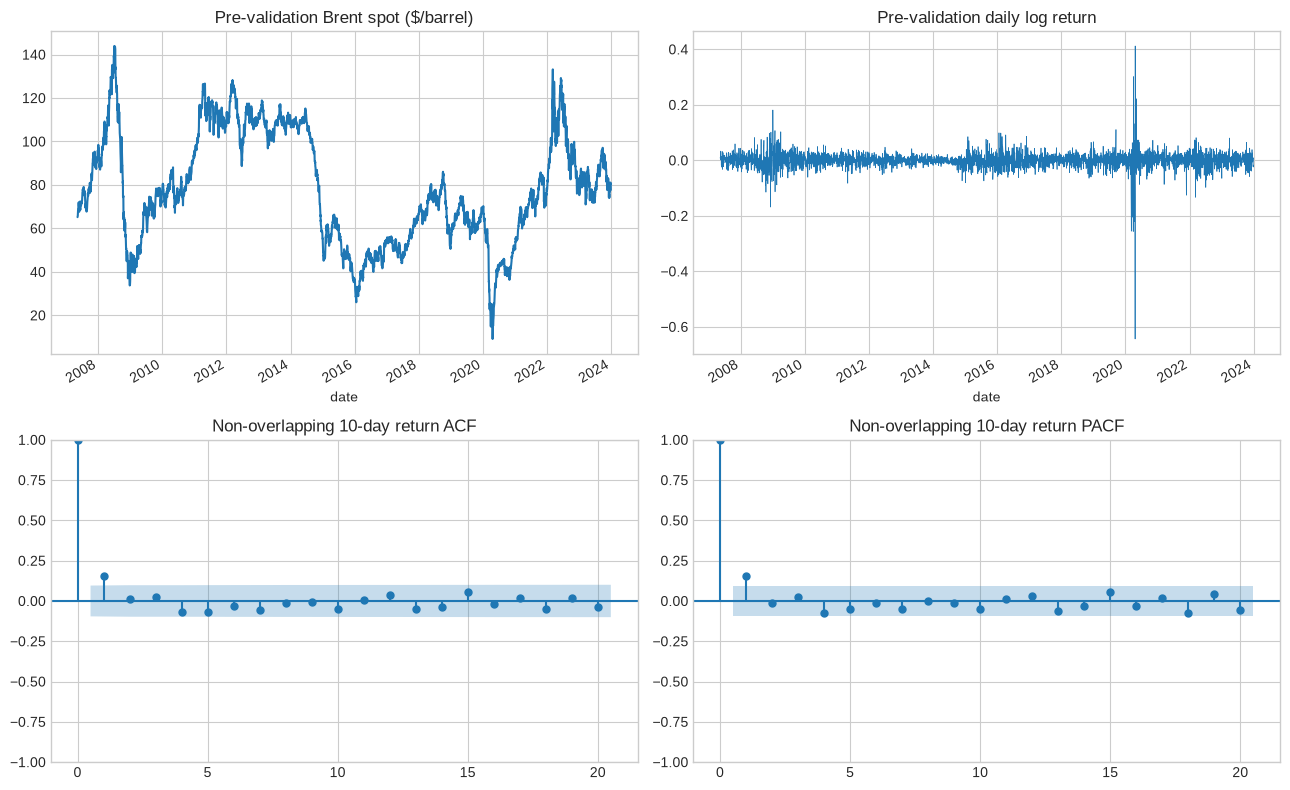

In [4]:
pre = df.loc[df.index < VAL_START]
r = pre.log_return
nonoverlap = r.rolling(H).sum().iloc[H-1::H].dropna()
diagnostic_rows = []
for label, series in [('log price', np.log(pre.brent_spot)), ('daily log return', r),
                      ('non-overlapping 10-day return', nonoverlap)]:
    a = adfuller(series, maxlag=20, autolag='AIC')
    diagnostic_rows.append({'series': label, 'ADF statistic': a[0], 'ADF p': a[1], 'n': a[3]})
diagnostics = pd.DataFrame(diagnostic_rows).set_index('series')
display(diagnostics.round(5))
display(acorr_ljungbox(r, lags=[10, 20], return_df=True))
arch_stat, arch_p, _, _ = het_arch(r * 100, nlags=10)
print(f'ARCH-LM(10): statistic={arch_stat:.3f}, p={arch_p:.5g}')
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
pre.brent_spot.plot(ax=axes[0, 0], title='Pre-validation Brent spot ($/barrel)')
r.plot(ax=axes[0, 1], title='Pre-validation daily log return', linewidth=0.5)
sm.graphics.tsa.plot_acf(nonoverlap, lags=20, ax=axes[1, 0])
sm.graphics.tsa.plot_pacf(nonoverlap, lags=20, ax=axes[1, 1], method='ywm')
axes[1, 0].set_title('Non-overlapping 10-day return ACF')
axes[1, 1].set_title('Non-overlapping 10-day return PACF')
plt.tight_layout(); plt.show()

## 4. Forecasting Models

| Family | Specifications | Forecasting approach |
|---|---|---|
| Benchmarks | Random walk, historical mean, AR(1) | No change, average drift and short-run persistence |
| ARIMA | (0,1,1), (1,1,1) on log prices | Iterated forecasts from ARMA models of daily log returns |
| Direct OLS | Trailing 10-day return; short/long windows (1,20), (5,60) | Direct regression of future 10-day returns on past returns |
| VAR | S1, S2 and S3; lag orders 1 and 3 | Joint daily forecasts aggregated to the Brent horizon |
| Spread mean reversion | Relative Brent–WTI spread | Direct return forecast from the observed spread |
| Ridge | Penalties 10 and 100 | Regularised regression using momentum, volatility and external inputs |
| XGBoost | 50 or 150 trees; depth 1 or 2 | Shallow nonlinear direct-return models |
| GARCH | Constant-mean GARCH(1,1), Student-t errors | Drift-based point forecast with time-varying volatility |
| Combination | Equal weights on RW, direct OLS and AR(1) | Averaging in log-return space |

The 23 candidates are specified before validation scoring. For each direct-model training pair, the target date must be no later than the fitting date. Iterated models forecast daily dynamics and aggregate them over the 10-day horizon.

GARCH primarily models uncertainty. A constant-mean version is included in the point-forecast comparison, while zero-mean GARCH supplies prediction intervals around the selected forecast. Model-fitting failures are reported rather than replaced by benchmark forecasts.

In [5]:
def arima_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK, order=(0, 1)):
    """ARMA(p,q) on daily log returns = ARIMA(p,1,q) on log prices."""
    if fit_idx > origin_idx or fit_idx - lookback + 1 < 0:
        raise ValueError('Invalid ARIMA fitting window.')
    window = frame.log_return.iloc[fit_idx-lookback+1:fit_idx+1].to_numpy() * 100
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        fitted = ARIMA(window, order=(order[0], 0, order[1]), trend='c').fit(
            method_kwargs={'maxiter': 300})
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('ARIMA optimisation did not converge.')
    if origin_idx > fit_idx:
        # Update the state with observed returns; parameters stay frozen.
        fitted = fitted.append(frame.log_return.iloc[fit_idx+1:origin_idx+1].to_numpy() * 100, refit=False)
    pred = float(np.sum(fitted.forecast(steps=horizon))) / 100
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(pred))

def garch_fit(frame, origin_idx, fit_idx, lookback=LOOKBACK, mean='Constant'):
    start = fit_idx - lookback + 1
    if not (0 <= start <= fit_idx <= origin_idx):
        raise ValueError('Invalid GARCH fitting window.')
    spec = dict(mean=mean, vol='GARCH', p=1, q=1, dist='t', rescale=False)
    fit = arch_model(frame.log_return.iloc[start:fit_idx+1].to_numpy()*100, **spec).fit(
        disp='off', show_warning=False, options={'maxiter': 1000})
    if fit.convergence_flag != 0:
        raise RuntimeError(f'GARCH failed to converge: {fit.optimization_result.message}')
    if origin_idx > fit_idx:
        fit = arch_model(frame.log_return.iloc[start:origin_idx+1].to_numpy()*100, **spec).fix(fit.params)
    return fit

def garch_mean_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK):
    fit = garch_fit(frame, origin_idx, fit_idx, lookback, mean='Constant')
    mu = float(fit.params['mu']) / 100
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(horizon * mu))

# Model inputs are backward looking. Future labels are built separately inside each fit.
def ridge_features(frame):
    F = make_lag_features(frame, ['log_return'], lags=3)
    for w in [5, 10, 20, 60]:
        F[f'momentum_{w}'] = frame.log_return.rolling(w).sum()
    F['vol_20'] = realised_volatility(frame, window=20)
    F['vol_60'] = realised_volatility(frame, window=60)
    if USE_EXOG:
        for c in ['wti', 'sp500', 'usd', 'vix', 'ovx']:
            F[c] = frame[c]  # already shifted in preprocessing
        F['spread'] = (frame.brent_spot - frame.wti_spot) / frame.brent_spot
    return F

RIDGE_FEATURES = ridge_features(df)
XGB_FEATURES = RIDGE_FEATURES.copy()

def ridge_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK, alpha=100):
    if not 0 <= fit_idx-lookback+1 <= fit_idx <= origin_idx:
        raise ValueError('Invalid ridge fitting window.')
    positions = np.arange(fit_idx-lookback+1, fit_idx-horizon+1)
    X = RIDGE_FEATURES.iloc[positions]
    y = np.log(frame.brent_spot.iloc[positions+horizon].to_numpy() /
               frame.brent_spot.iloc[positions].to_numpy())
    keep = np.isfinite(X.to_numpy()).all(axis=1) & np.isfinite(y)
    assert positions.max() + horizon <= fit_idx
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    pipe.fit(X.loc[keep], y[keep])
    pred = float(pipe.predict(RIDGE_FEATURES.iloc[[origin_idx]])[0])
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(pred))

def combination_forecast(frame, origin_idx, horizon, fit_idx):
    members = [random_walk_forecast,
               partial(direct_forecast, lookback=LOOKBACK),
               partial(ar1_forecast, lookback=LOOKBACK)]
    p0 = frame.brent_spot.iloc[origin_idx]
    ret = [np.log(fn(frame, origin_idx, horizon, fit_idx)/p0) for fn in members]
    return float(p0 * np.exp(np.mean(ret)))

MODELS, SPECS = {}, {}
def register(name, fn, family, complexity, **kwargs):
    MODELS[name] = partial(fn, **kwargs)
    SPECS[name] = {'family': family, 'complexity': complexity,
                   'function': fn.__name__, 'parameters': {k: str(v) for k, v in kwargs.items()}}

register('Random Walk', random_walk_forecast, 'Benchmark', 0)
register('Historical Mean', historical_mean_forecast, 'Benchmark', 1, lookback=LOOKBACK)
register('AR(1)', ar1_forecast, 'Benchmark', 2, lookback=LOOKBACK)
for pq in [(0, 1), (1, 1)]:
    register(f'ARIMA({pq[0]},1,{pq[1]})', arima_forecast, 'ARIMA', 3+sum(pq), order=pq)
register('Direct OLS (10d)', direct_forecast, 'Direct', 3, lookback=LOOKBACK)
for short, long in [(1, 20), (5, 60)]:
    register(f'Direct lags ({short},{long})', direct_lags_forecast, 'Direct', 4,
             lookback=LOOKBACK, short=short, long=long, nonoverlap=True)
if USE_EXOG:
    stages = {'S1': ['log_return', 'wti', 'sp500'],
              'S2': ['log_return', 'wti', 'sp500', 'usd', 'vix'],
              'S3': ['log_return', 'wti', 'sp500', 'usd', 'vix', 'ovx']}
    for stage, cols in stages.items():
        for p in [1, 3]:
            register(f'VAR {stage} p={p}', var_forecast, 'VAR', 10+len(cols)*p,
                     cols=cols, lags=p, lookback=LOOKBACK)
    register('Spread mean reversion', spread_mr_forecast, 'Spread', 4, lookback=LOOKBACK)
for alpha in [10, 100]:
    register(f'Ridge alpha={alpha}', ridge_forecast, 'Ridge', 20, alpha=alpha)
for n in [50, 150]:
    for depth in [1, 2]:
        # Large input DataFrame is bound separately, not serialised into the spec table.
        name = f'XGB n={n} depth={depth}'
        register(name, xgb_forecast, 'XGBoost', 30+depth*2+n/1000,
                 lookback=LOOKBACK, n_estimators=n, max_depth=depth,
                 min_child_weight=20, learning_rate=0.03)
        MODELS[name] = partial(MODELS[name], features=XGB_FEATURES)
register('GARCH(1,1)-t mean', garch_mean_forecast, 'GARCH', 6)
register('Fixed combination', combination_forecast, 'Combination', 8)
display(pd.DataFrame(SPECS).T[['family', 'function', 'parameters']])
print(len(MODELS), 'candidates, declared before scoring. Complexity is an explicit tie-break ranking, not parameter count.')

,family,function,parameters
Random Walk,Benchmark,random_walk_forecast,{}
Historical Mean,Benchmark,historical_mean_forecast,{'lookback': '3000'}
AR(1),Benchmark,ar1_forecast,{'lookback': '3000'}
"ARIMA(0,1,1)",ARIMA,arima_forecast,"{'order': '(0, 1)'}"
"ARIMA(1,1,1)",ARIMA,arima_forecast,"{'order': '(1, 1)'}"
Direct OLS (10d),Direct,direct_forecast,{'lookback': '3000'}
"Direct lags (1,20)",Direct,direct_lags_forecast,"{'lookback': '3000', 'short': '1', 'long': '20..."
"Direct lags (5,60)",Direct,direct_lags_forecast,"{'lookback': '3000', 'short': '5', 'long': '60..."
VAR S1 p=1,VAR,var_forecast,"{'cols': '['log_return', 'wti', 'sp500']', 'la..."
VAR S1 p=3,VAR,var_forecast,"{'cols': '['log_return', 'wti', 'sp500']', 'la..."


23 candidates, declared before scoring. Complexity is an explicit tie-break ranking, not parameter count.


### Walk-Forward Backtesting

At each origin, the latest available rolling history is used to estimate the model and forecast 10 observed Brent trading days ahead. Origin bounds and target cutoffs are enforced separately.

Every candidate is scored on identical origin–target pairs within each period. There is no shuffled train/test split. Training-label and calendar assertions check that no future targets enter estimation and every historical target is exactly 10 Brent observations after its origin.

In [6]:
def checked_model(fn, model_name):
    def forecast(frame, origin_idx, horizon, fit_idx):
        assert fit_idx <= origin_idx
        assert fit_idx >= LOOKBACK - 1
        try:
            result = float(fn(frame, origin_idx, horizon, fit_idx))
            if not np.isfinite(result) or result <= 0:
                raise ValueError(f'Invalid price forecast {result}')
            return result
        except Exception as exc:
            raise RuntimeError(f'{model_name}: origin {frame.index[origin_idx].date()}, '
                               f'fit through {frame.index[fit_idx].date()}: {exc}') from exc
    return forecast

def run_target_window(fn, name, target_start, target_end, origin_min=None, origin_max=None, fit_cutoff=None):
    dates = df.index
    js = np.arange(len(dates))
    eligible = (dates >= pd.Timestamp(target_start)) & (dates <= pd.Timestamp(target_end)) & (js >= H)
    targets = js[eligible]
    if origin_min is not None:
        targets = targets[dates[targets-H] >= pd.Timestamp(origin_min)]
    if origin_max is not None:
        targets = targets[dates[targets-H] < pd.Timestamp(origin_max)]
    if len(targets) == 0:
        raise ValueError(f'{name}: no available targets for this window.')
    origins = targets - H
    end = dates[origins[-1]] + pd.Timedelta(days=1)  # shared end_date is exclusive
    res = walk_forward(df, horizon=H, start_date=dates[origins[0]], end_date=end,
                       forecast_funct=checked_model(fn, name),
                       fit_end_date=fit_cutoff, target_end_date=pd.Timestamp(target_end))
    res = res.loc[res.target_date.between(pd.Timestamp(target_start), pd.Timestamp(target_end))].reset_index(drop=True)
    assert len(res) == len(targets)
    assert pd.DatetimeIndex(res.origin_date).equals(dates[origins])
    assert pd.DatetimeIndex(res.target_date).equals(dates[targets])
    assert (res.actual.to_numpy() == df.brent_spot.iloc[targets].to_numpy()).all()
    return res

def assert_common(results):
    keys = ['origin_date', 'target_date']
    first = next(iter(results.values()))
    for name, res in results.items():
        assert not res.duplicated(keys).any(), name
        assert res[keys].equals(first[keys]), f'Different evaluation dates: {name}'
        np.testing.assert_allclose(res.actual, first.actual)
        np.testing.assert_allclose(res.origin_price, first.origin_price)
    return len(first)

# Check the direct-label boundary and causality at a representative PRE-validation origin.
probe = np.flatnonzero(df.index < VAL_START)[-1]
positions = np.arange(probe-LOOKBACK+1, probe-H+1)
assert positions[-1] + H == probe
np.testing.assert_allclose(
    df.log_return.rolling(H).sum().shift(-H).iloc[positions],
    np.log(df.brent_spot.iloc[positions+H].to_numpy()/df.brent_spot.iloc[positions].to_numpy()),
    atol=1e-12)
# Future-price perturbation must not alter any already-known features.
altered = df.copy()
altered.loc[altered.index > df.index[probe], ['brent_spot', 'log_return']] *= 1.5
pd.testing.assert_frame_equal(ridge_features(df).iloc[:probe+1], ridge_features(altered).iloc[:probe+1])
print('Training-label boundary, causal feature construction, and observed-calendar checks passed.')

Training-label boundary, causal feature construction, and observed-calendar checks passed.


## 5. Validation and Model Selection

Each candidate is re-estimated at validation origins beginning in January 2024, with all scored outcomes observed by **31 December 2025**. The origin upper bound is exclusive and the target cutoff inclusive.

The primary criterion is **MAPE**. Candidates within **0.002 MAPE percentage points** of the minimum are treated as near ties, with preference given to a prespecified simpler specification. The winner and family representatives are fixed before the January–September 2026 test is evaluated.

In [7]:
validation_results = {}
for name, fn in MODELS.items():
    started = time.perf_counter()
    validation_results[name] = run_target_window(
        fn, name, VAL_START, SELECTION_END, origin_min=VAL_START, origin_max=VAL_END)
    print(f'{name:28s} {len(validation_results[name]):4d} forecasts, '
          f'{time.perf_counter()-started:6.1f}s', flush=True)
N_VAL = assert_common(validation_results)
assert all(r.target_date.max() < FIRST_TEST_ORIGIN for r in validation_results.values())
print('Validation forecast pairs per model:', N_VAL)

Random Walk                   497 forecasts,    0.0s


Historical Mean               497 forecasts,    0.0s


AR(1)                         497 forecasts,    0.6s


ARIMA(0,1,1)                  497 forecasts,   29.6s


ARIMA(1,1,1)                  497 forecasts,   75.8s


...

XGB n=150 depth=1             497 forecasts,   14.4s


XGB n=150 depth=2             497 forecasts,   21.1s


GARCH(1,1)-t mean             497 forecasts,    8.5s


Fixed combination             497 forecasts,    1.0s


Validation forecast pairs per model: 497


### Evaluation Metrics

MAE and RMSE are in USD/barrel, and MAPE is percent. Relative gains over random walk are positive when a candidate has lower loss. Directional accuracy, precision, recall and F1 are fractions in the comparison tables. Random walk predicts no price change, so its directional classification metrics are not applicable.

`compare_models_staggered` combines the same accuracy and directional calculations with daily staggered economic metrics. Return, volatility and drawdown fields are fractions in the raw comparison CSVs; the separate economic summaries display percentages. Sharpe remains dimensionless. Selection continues to use MAPE rather than Sharpe.

In [8]:
DIRECTION_COLS = ['directional_accuracy', 'precision_up', 'recall_up', 'f1_up',
                  'precision_down', 'recall_down', 'f1_down']

def comparison_table(results):
    assert_common(results)
    table = compare_models_staggered(results, horizon=H)
    # Shared field is mean |NET exposure|, despite its original gross-exposure label.
    table = table.rename(columns={'avg_gross_exposure': 'avg_abs_net_exposure'})
    for name, res in results.items():
        if np.allclose(res.forecast, res.origin_price, atol=1e-10, rtol=0):
            table.loc[name, DIRECTION_COLS] = np.nan
    for metric in ['MAE', 'RMSE', 'MAPE']:
        table[f'{metric}_vs_RW_%'] = 100*(1-table[metric]/table.loc['Random Walk', metric])
    return table

val_table = comparison_table(validation_results)
val_table['complexity'] = [SPECS[n]['complexity'] for n in val_table.index]
val_table['family'] = [SPECS[n]['family'] for n in val_table.index]
best_mape = val_table.MAPE.min()
near_ties = val_table.loc[val_table.MAPE <= best_mape + TIE_PP]
WINNER = near_ties.sort_values(['complexity', 'MAPE'], kind='stable').index[0]
FAMILY_WINNERS = []
for family in dict.fromkeys(v['family'] for v in SPECS.values()):
    group = val_table.loc[val_table.family == family]
    tied = group.loc[group.MAPE <= group.MAPE.min()+TIE_PP]
    FAMILY_WINNERS.append(tied.sort_values(['complexity', 'MAPE'], kind='stable').index[0])
# All benchmarks plus the validation-selected representative of each family; fixed before test.
SHORTLIST = list(dict.fromkeys(['Random Walk', 'Historical Mean', 'AR(1)', *FAMILY_WINNERS, WINNER]))
locked_winner = WINNER
selection_record = {
    'winner': WINNER, 'horizon_observations': H, 'lookback': LOOKBACK,
    'validation_origin_start': str(VAL_START.date()),
    'validation_origin_end_exclusive': str(VAL_END.date()),
    'validation_target_end': str(SELECTION_END.date()),
    'first_test_origin': str(FIRST_TEST_ORIGIN.date()),
    'test_origin_bounds': [str(TEST_START.date()), str(TEST_END.date())],
    'test_target_end': str(TEST_TARGET_END.date()),
    'test_fit_policy': 'rolling_refits_at_each_origin',
    'final_forecast_origin': str(FINAL_ORIGIN.date()),
    'tie_rule_MAPE_percentage_points': TIE_PP, 'input_sha256': DATA_HASH,
    'shortlist': SHORTLIST, 'candidate_specs': SPECS,
    'economic_method': 'compare_models_staggered',
    'economic_source_commit': METRICS_SOURCE_COMMIT,
    'transaction_cost_per_net_exposure_unit': TRANSACTION_COST,
}
(OUT/'selection_lock.json').write_text(json.dumps(selection_record, indent=2))
display(val_table[['MAE', 'RMSE', 'MAPE', 'MAPE_vs_RW_%', 'directional_accuracy', 'family']]
        .sort_values('MAPE').round(4))
print('LOCKED MODEL:', WINNER)
print('Best raw validation MAPE:', round(best_mape, 5), '; tie tolerance:', TIE_PP, 'percentage points')
print('This winner will NOT be replaced using test results or a significance-test p-value.')

,MAE,RMSE,MAPE,MAPE_vs_RW_%,directional_accuracy,family
model,,,,,,
VAR S3 p=3,3.0172,3.9457,4.0450,0.7447,0.5634,VAR
"ARIMA(1,1,1)",3.0222,3.9616,4.0502,0.6186,0.5312,ARIMA
VAR S1 p=3,3.0265,3.9605,4.0564,0.4660,0.5211,VAR
Spread mean reversion,3.0276,3.9673,4.0588,0.4073,0.5292,Spread
VAR S3 p=1,3.0256,3.9678,4.0611,0.3503,0.5433,VAR
VAR S1 p=1,3.0324,3.9704,4.0656,0.2394,0.5171,VAR
"ARIMA(0,1,1)",3.0348,3.9753,4.0691,0.1526,0.5191,ARIMA
AR(1),3.0353,3.9757,4.0699,0.1346,0.5252,Benchmark
Historical Mean,3.0378,3.9781,4.0736,0.0437,0.5412,Benchmark


LOCKED MODEL: VAR S3 p=3
Best raw validation MAPE: 4.04501 ; tie tolerance: 0.002 percentage points
This winner will NOT be replaced using test results or a significance-test p-value.


## 6. Daily Staggered Economic Performance

A new long, short or flat signal is formed at each origin close. Each position receives **1/10 of capital** and is held for 10 observed Brent trading intervals. The next day's net exposure is the average of the previous 10 signals; future signals never enter that day's return.

The one-day strategy return is net exposure times the one-day Brent return, less **1 basis point per unit change in net exposure**. Opposing cohorts are netted before trading costs are assessed. Annualised arithmetic return is mean daily net return × 252; annualised volatility is daily standard deviation × √252; Sharpe is their ratio, with a zero risk-free rate assumption. There is no additional horizon multiplier for these one-day portfolio returns.

The shared implementation measures only days with a full signal history and defined turnover while origins are still available. Start-up and terminal run-off days are excluded, so economic-return dates differ from the forecast-target window. All models use the same daily evaluation dates within each stage.

`annual_turnover` is annualised net exposure turnover, not a trade count. The shared field originally called `avg_gross_exposure` equals mean absolute **net** exposure and is labelled accordingly here. Equity and drawdown follow the shared implementation. Daily observations may remain serially dependent; conventional annualised Sharpe is descriptive, not evidence of independent returns or a reliable trading edge. The proxy omits futures rolls, financing, margin and slippage.

In [9]:
def daily_staggered_path(res, horizon=H, cost=TRANSACTION_COST):
    """Reproduce the shared helper's daily path for audit and plotting only."""
    assert not res.duplicated('origin_date').any()
    px = pd.concat([res.set_index('origin_date').origin_price,
                    res.set_index('target_date').actual])
    px = px.loc[~px.index.duplicated()].sort_index()
    # A return must span one observed Brent interval, not several missing observations.
    locations = df.index.get_indexer(px.index)
    assert (locations >= 0).all() and (np.diff(locations) == 1).all()
    signal = np.sign(res.forecast-res.origin_price)
    signal.index = res.origin_date
    signal = signal.reindex(px.index)
    daily_return = px.pct_change()
    exposure = signal.shift(1).rolling(horizon).mean()
    turnover = exposure.diff().abs()
    net = exposure*daily_return-cost*turnover
    full = signal.notna().to_numpy() & exposure.notna().to_numpy()
    # The first fully invested row has undefined previous exposure; the shared function drops it.
    daily = pd.DataFrame({'price': px, 'spot_return': daily_return,
                          'net_exposure': exposure, 'net_turnover': turnover,
                          'net_return': net}).loc[full].iloc[1:].copy()
    daily['equity'] = (1+daily.net_return).cumprod()
    daily.index.name = 'date'
    assert np.isfinite(daily.to_numpy()).all()
    # Audit the displayed path against the group's authoritative summary calculation.
    shared = economic_value_staggered(res, horizon=horizon, transaction_cost=cost)
    assert len(daily) == shared['n_days']
    np.testing.assert_allclose(daily.net_return.mean()*252, shared['annualized_return'], atol=1e-12)
    np.testing.assert_allclose(daily.net_return.std()*np.sqrt(252), shared['annualized_vol'], atol=1e-12)
    np.testing.assert_allclose((daily.equity/daily.equity.cummax()-1).min(), shared['max_drawdown'], atol=1e-12)
    return daily

validation_paths = {name: daily_staggered_path(res) for name, res in validation_results.items()}

def economic_display(table, names):
    report = table.loc[names, ['annualized_return', 'annualized_vol', 'sharpe_ratio',
                               'max_drawdown', 'annual_turnover', 'avg_abs_net_exposure', 'n_days']].copy()
    for column in ['annualized_return', 'annualized_vol', 'max_drawdown', 'avg_abs_net_exposure']:
        report[column] *= 100
    return report.rename(columns={'annualized_return': 'Annualised arithmetic return %',
                                  'annualized_vol': 'Annualised volatility %',
                                  'sharpe_ratio': 'Daily-return Sharpe',
                                  'max_drawdown': 'Max drawdown %',
                                  'annual_turnover': 'Annual net turnover (units)',
                                  'avg_abs_net_exposure': 'Mean absolute net exposure %',
                                  'n_days': 'Daily observations'})

economic_validation = economic_display(val_table, SHORTLIST)
display(economic_validation.round(4))
economic_periods = [{'stage': 'validation', 'first_daily_return': p.index.min(),
                     'last_daily_return': p.index.max(), 'n_days': len(p)}
                    for p in [validation_paths[WINNER]]]
print('Shared daily staggered trading method; each origin contributes 1/H of the capital.')
print('Daily portfolio window:', validation_paths[WINNER].index[0].date(), 'to',
      validation_paths[WINNER].index[-1].date())

,Annualised arithmetic return %,Annualised volatility %,Daily-return Sharpe,Max drawdown %,Annual net turnover (units),Mean absolute net exposure %,Daily observations
model,,,,,,,
Random Walk,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,486
Historical Mean,9.5975,28.6100,0.3355,-26.3059,0.0000,100.0000,486
AR(1),6.0172,27.8252,0.2162,-26.3059,1.2444,96.7078,486
"ARIMA(1,1,1)",8.9537,21.4314,0.4178,-21.1725,13.1704,69.0535,486
"Direct lags (5,60)",-2.3427,20.2071,-0.1159,-27.7504,18.6667,58.8477,486
VAR S3 p=3,18.0714,18.6637,0.9683,-12.3861,19.2889,57.7366,486
Spread mean reversion,7.3545,25.7404,0.2857,-24.8735,5.6000,88.4774,486
Ridge alpha=100,11.2458,26.2345,0.4287,-22.4566,6.6370,90.5761,486
XGB n=50 depth=1,9.5975,28.6100,0.3355,-26.3059,0.0000,100.0000,486


Shared daily staggered trading method; each origin contributes 1/H of the capital.
Daily portfolio window: 2024-01-17 to 2025-12-15


## 7. Forecast-Accuracy Significance Tests

Diebold–Mariano tests compare expected forecast loss. Absolute percentage error is the primary loss and squared error a secondary specification. Negative statistics favour the candidate over its named benchmark.

Bartlett/Newey–West long-run variance and the Harvey–Leybourne–Newbold adjustment account for dependent overlapping forecasts and finite samples. Lag 9 addresses mechanical 10-day overlap; validation lag 20 is a sensitivity check. Holm adjustment covers all searched candidates within each validation loss/bandwidth table.

Validation p-values are selection-period diagnostics. Separate test comparisons use only the prespecified shortlist, with Holm adjustment within each benchmark/loss table. A small p-value supports unequal expected loss under the test assumptions; the sign and magnitude of the difference remain essential. Overlap, limited effective sample size and retrospective study design constrain interpretation.

In [10]:
def dm_test(a, b, horizon=H, loss='ape', bandwidth=None):
    keys = ['origin_date', 'target_date']
    m = a[keys+['actual', 'forecast']].merge(
        b[keys+['actual', 'forecast']], on=keys, suffixes=('_a', '_b'), validate='one_to_one').sort_values('origin_date')
    np.testing.assert_allclose(m.actual_a, m.actual_b)
    ea, eb = m.actual_a-m.forecast_a, m.actual_b-m.forecast_b
    loss_fn = {'ape': lambda e: e.abs()/m.actual_a, 'se': lambda e: e**2, 'ae': lambda e: e.abs()}[loss]
    d = (loss_fn(ea)-loss_fn(eb)).to_numpy()
    n = len(d)
    out = {'n': n, 'mean_loss_gap': np.mean(d) if n else np.nan,
           'DM': np.nan, 'p_raw': np.nan, 'note': ''}
    if n < 5*horizon:
        out['note'] = 'Too few overlapping forecasts for a reliable DM interpretation; p-value suppressed.'
        return out
    L = min(horizon-1 if bandwidth is None else bandwidth, n-1)
    dc = d-d.mean()
    lrv = dc@dc/n + 2*sum((1-k/(L+1))*(dc[k:]@dc[:-k])/n for k in range(1, L+1))
    if lrv <= 1e-20:
        out['note'] = 'Degenerate loss differential; no valid standard error.'
        return out
    correction = (n+1-2*horizon+horizon*(horizon-1)/n)/n
    dm = d.mean()/np.sqrt(lrv/n)*np.sqrt(correction)
    out.update(DM=float(dm), p_raw=float(2*stats.t.sf(abs(dm), n-1)))
    return out

def dm_comparison(results, loss='ape', bandwidth=H-1, benchmark='Random Walk'):
    rows = {n: dm_test(r, results[benchmark], loss=loss, bandwidth=bandwidth)
            for n, r in results.items() if n != benchmark}
    table = pd.DataFrame(rows).T
    table['p_Holm'] = np.nan
    valid = pd.to_numeric(table.p_raw, errors='coerce').notna()
    if valid.any():
        table.loc[valid, 'p_Holm'] = multipletests(table.loc[valid, 'p_raw'].astype(float), method='holm')[1]
    return table

dm_tables = {}
for loss, bandwidth in [('ape', H-1), ('se', H-1), ('ape', 20)]:
    key = f'{loss}_lag{bandwidth}'
    dm_tables[key] = dm_comparison(validation_results, loss, bandwidth)
    print(f'Validation DM versus Random Walk: {loss}, HAC lag {bandwidth}')
    display(dm_tables[key].loc[[n for n in SHORTLIST if n != 'Random Walk']].round(5))

Validation DM versus Random Walk: ape, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,497,-0.000018,-0.157787,0.874689,,1.00000
AR(1),497,-0.000055,-0.483176,0.629184,,1.00000
"ARIMA(1,1,1)",497,-0.000252,-1.806322,0.071474,,1.00000
"Direct lags (5,60)",497,0.000226,0.717331,0.473507,,1.00000
VAR S3 p=3,497,-0.000304,-0.605928,0.544839,,1.00000
Spread mean reversion,497,-0.000166,-1.63289,0.103127,,1.00000
Ridge alpha=100,497,0.001203,1.027014,0.304915,,1.00000
XGB n=50 depth=1,497,0.000116,0.35128,0.725528,,1.00000
"GARCH(1,1)-t mean",497,0.00087,2.174818,0.030116,,0.60231
Fixed combination,497,0.000291,1.990156,0.047122,,0.89532


Validation DM versus Random Walk: se, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,497,0.011203,0.146037,0.883952,,1.0000
AR(1),497,-0.007475,-0.09382,0.92529,,1.0000
"ARIMA(1,1,1)",497,-0.119159,-1.103178,0.270485,,1.0000
"Direct lags (5,60)",497,0.142899,0.722752,0.470173,,1.0000
VAR S3 p=3,497,-0.245365,-0.631891,0.527749,,1.0000
Spread mean reversion,497,-0.074571,-1.111934,0.266705,,1.0000
Ridge alpha=100,497,0.85794,1.032539,0.302323,,1.0000
XGB n=50 depth=1,497,0.059293,0.302586,0.762332,,1.0000
"GARCH(1,1)-t mean",497,0.468898,1.548761,0.122077,,1.0000
Fixed combination,497,0.224893,2.207803,0.027715,,0.5543


Validation DM versus Random Walk: ape, HAC lag 20


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,497,-0.000018,-0.173239,0.862534,,1.00000
AR(1),497,-0.000055,-0.533472,0.593946,,1.00000
"ARIMA(1,1,1)",497,-0.000252,-1.947376,0.052054,,0.93696
"Direct lags (5,60)",497,0.000226,0.657866,0.51093,,1.00000
VAR S3 p=3,497,-0.000304,-0.639381,0.522871,,1.00000
Spread mean reversion,497,-0.000166,-1.720687,0.085931,,1.00000
Ridge alpha=100,497,0.001203,1.151144,0.250228,,1.00000
XGB n=50 depth=1,497,0.000116,0.383861,0.701246,,1.00000
"GARCH(1,1)-t mean",497,0.00087,2.19224,0.028826,,0.57652
Fixed combination,497,0.000291,2.104296,0.035855,,0.68125


## 8. Robustness and Validation Figures

Accuracy is compared by target year and by high- and low-volatility regimes. Regimes use trailing 20-day realised volatility available at the origin, with the threshold fixed at the pre-2024 median.

Yearly tables and rolling losses indicate whether an average advantage is concentrated in particular periods. The economic figure compounds the shared method's daily staggered net returns. These diagnostics do not introduce another model-selection round.

Fixed pre-validation high-volatility threshold: 1.90% daily


group,2024,2025,high volatility,low volatility
model,,,,
AR(1),3.6216,4.5022,3.9517,4.1250
"ARIMA(1,1,1)",3.6142,4.4706,3.9037,4.1184
"Direct lags (5,60)",3.6160,4.5627,4.0961,4.0988
Fixed combination,3.6326,4.5595,4.0157,4.1458
"GARCH(1,1)-t mean",3.6916,4.6165,3.9969,4.2395
Historical Mean,3.6240,4.5072,3.9603,4.1264
Random Walk,3.6185,4.5159,3.9517,4.1330
Ridge alpha=100,3.6979,4.6757,4.0411,4.2677
Spread mean reversion,3.6182,4.4837,3.9325,4.1176


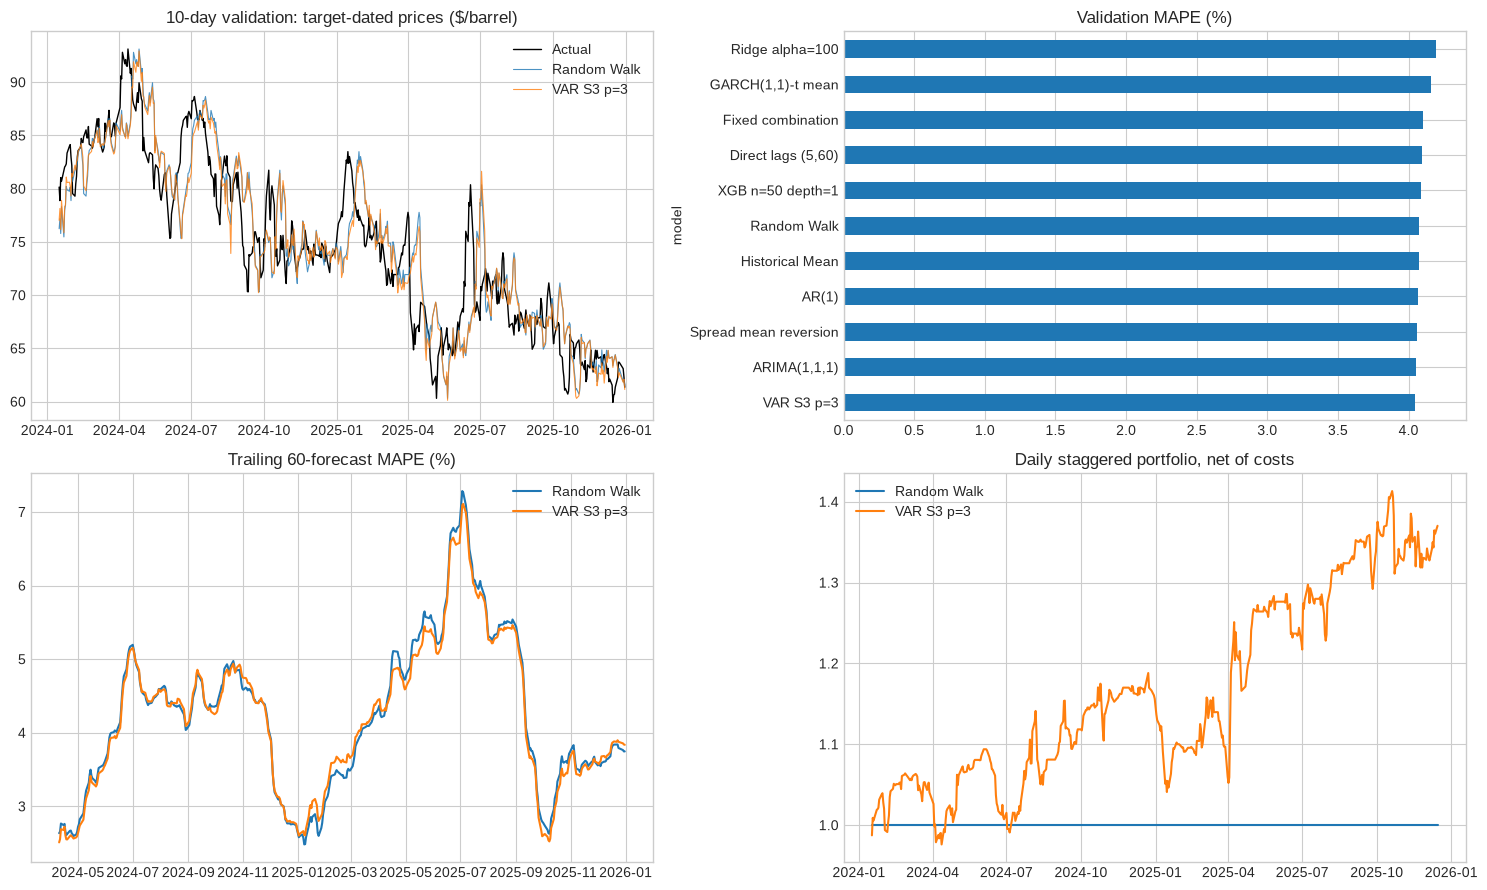

In [11]:
volatility = realised_volatility(df, window=20)
VOL_THRESHOLD = volatility.loc[volatility.index < VAL_START].median()
robust_rows = []
for name in SHORTLIST:
    res = validation_results[name]
    high = volatility.reindex(pd.DatetimeIndex(res.origin_date)).to_numpy() >= VOL_THRESHOLD
    groups = {'high volatility': high, 'low volatility': ~high}
    for year in sorted(res.target_date.dt.year.unique()):
        groups[str(year)] = res.target_date.dt.year.to_numpy() == year
    for group, mask in groups.items():
        if mask.sum():
            robust_rows.append({'model': name, 'group': group, 'n': int(mask.sum()),
                                **accuracy_metrics(res.loc[mask])})
robustness = pd.DataFrame(robust_rows)
print(f'Fixed pre-validation high-volatility threshold: {VOL_THRESHOLD:.2%} daily')
display(robustness.pivot(index='model', columns='group', values='MAPE').round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
selected = validation_results[WINNER]
axes[0, 0].plot(selected.target_date, selected.actual, label='Actual', color='black', lw=1)
for name in list(dict.fromkeys(['Random Walk', WINNER])):
    r = validation_results[name]
    axes[0, 0].plot(r.target_date, r.forecast, label=name, alpha=0.8, lw=0.8)
axes[0, 0].set_title('10-day validation: target-dated prices ($/barrel)'); axes[0, 0].legend()
val_table.loc[SHORTLIST, 'MAPE'].sort_values().plot.barh(ax=axes[0, 1], title='Validation MAPE (%)')
for name in list(dict.fromkeys(['Random Walk', WINNER])):
    r = validation_results[name]
    ape = (r.actual-r.forecast).abs()/r.actual*100
    axes[1, 0].plot(r.target_date, ape.rolling(60).mean(), label=name)
    curve = validation_paths[name]
    axes[1, 1].plot(curve.index, curve.equity, label=name)
axes[1, 0].set_title('Trailing 60-forecast MAPE (%)'); axes[1, 0].legend()
axes[1, 1].set_title('Daily staggered portfolio, net of costs'); axes[1, 1].legend()
plt.tight_layout(); plt.show()

## 9. Prediction Intervals

GARCH and constant-volatility intervals are evaluated around the same point forecasts. Zero-mean GARCH(1,1) with Student-t errors is fitted using returns available by the estimation date. Frozen-parameter volatility states are subsequently updated using observed returns only.

GARCH intervals use Monte Carlo Student-t innovations with variance updated along each simulated path. Equal-tailed **95% prediction bounds** are constructed in log-return space and converted to prices. The benchmark uses constant fitting-window variance and Normal cumulative innovations. Simulation uses a fixed random seed.

Interval performance is measured by coverage, mean width and the **Winkler score**, which penalises both wide intervals and missed observations. Lower scores are preferable. These approximate conditional intervals omit parameter and model uncertainty. Overlapping forecast outcomes invalidate a simple independent-binomial coverage test.

In [12]:
INTERVAL_LEVEL, N_SIM = 0.95, 4000

def garch_noise_paths(frame, origin_idx, fit_idx, horizon=H, n_sim=N_SIM, mean='Zero'):
    fit = garch_fit(frame, origin_idx, fit_idx, mean=mean)
    nu = float(fit.params['nu'])
    omega, alpha, beta = [float(fit.params[k]) for k in ['omega', 'alpha[1]', 'beta[1]']]
    eps_last = float(np.asarray(fit.resid)[-1])
    var_last = float(np.asarray(fit.conditional_volatility)[-1])**2
    rng = np.random.default_rng(SEED + origin_idx)
    variance = np.full(n_sim, omega + alpha*eps_last**2 + beta*var_last)
    total = np.zeros(n_sim)
    for _ in range(horizon):
        shock = np.sqrt(variance)*rng.standard_t(nu, size=n_sim)*np.sqrt((nu-2)/nu)
        total += shock/100
        variance = omega + alpha*shock**2 + beta*variance
    return total

def interval_row(frame, origin_idx, fit_idx, point, method='GARCH'):
    p0 = float(frame.brent_spot.iloc[origin_idx])
    center = np.log(point/p0)
    tail = (1-INTERVAL_LEVEL)/2
    if method == 'GARCH':
        paths = garch_noise_paths(frame, origin_idx, fit_idx)
        lo, hi = np.quantile(paths, [tail, 1-tail])
    elif method == 'Constant vol':
        sd = frame.log_return.iloc[fit_idx-LOOKBACK+1:fit_idx+1].std(ddof=1)*np.sqrt(H)
        lo, hi = stats.norm.ppf([tail, 1-tail])*sd
    else:
        raise ValueError(method)
    return p0*np.exp(center+lo), p0*np.exp(center+hi)

def add_intervals(res, method='GARCH', freeze=None):
    out = res.copy()
    lower, upper = [], []
    for row in res.itertuples(index=False):
        i = df.index.get_loc(row.origin_date)
        f = i if freeze is None else min(i, df.index.searchsorted(freeze, side='right')-1)
        lo, hi = interval_row(df, i, f, row.forecast, method)
        lower.append(lo); upper.append(hi)
    out['lower'], out['upper'] = lower, upper
    assert (out.lower > 0).all() and (out.upper >= out.lower).all()
    return out

def interval_metrics(res):
    alpha = 1-INTERVAL_LEVEL
    width = res.upper-res.lower
    score = width + 2/alpha*(res.lower-res.actual).clip(lower=0) + 2/alpha*(res.actual-res.upper).clip(lower=0)
    return {'n': len(res), 'nominal_coverage': INTERVAL_LEVEL,
            'coverage': res.actual.between(res.lower, res.upper).mean(),
            'mean_width_USD': width.mean(), 'Winkler_score': score.mean()}

val_intervals = {}
for method in ['GARCH', 'Constant vol']:
    # Fit interval noise once per date, then recenter for the two point models.
    rw_band = add_intervals(validation_results['Random Walk'], method)
    for name in list(dict.fromkeys(['Random Walk', WINNER])):
        band = rw_band.copy()
        ratio = validation_results[name].forecast.to_numpy()/rw_band.forecast.to_numpy()
        band['forecast'] = validation_results[name].forecast.to_numpy()
        band['lower'] *= ratio; band['upper'] *= ratio
        val_intervals[f'{name} | {method}'] = band
    print('Completed validation intervals:', method, flush=True)
interval_table = pd.DataFrame({n: interval_metrics(r) for n, r in val_intervals.items()}).T
display(interval_table.round(4))

Completed validation intervals: GARCH


Completed validation intervals: Constant vol


,n,nominal_coverage,coverage,mean_width_USD,Winkler_score
Random Walk | GARCH,497.0,0.95,0.9557,18.2421,21.3296
VAR S3 p=3 | GARCH,497.0,0.95,0.9618,18.2083,20.9323
Random Walk | Constant vol,497.0,0.95,1.0000,27.3147,27.3147
VAR S3 p=3 | Constant vol,497.0,0.95,1.0000,27.2505,27.2505


## 10. January–September 2026 Test Evaluation

The prespecified shortlist is evaluated at origins from **1 January 2026**, with an exclusive origin upper bound and inclusive target cutoff of **30 September 2026**. Each forecast is fitted using information through its origin; test rankings do not change the selected specification.

Accuracy, direction and DM tests use the common 10-day forecast pairs. Daily economic metrics use the shared staggered portfolio, with a separate daily-return window determined by its full-history rule. Prediction intervals are evaluated on the forecast-target dates. Sample counts for forecasts and daily portfolio returns are reported separately.

Test forecast pairs: 179 ; last target: 2026-09-30
Validation-selected specification: VAR S3 p=3


,MAE,RMSE,MAPE,MAPE_vs_RW_%,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,annual_turnover,n_days
model,,,,,,,,,,,,,,,,
Random Walk,10.7037,13.7336,11.0218,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,0.0000,0.0,168
Historical Mean,10.7364,13.7573,11.0599,-0.3464,0.3017,0.3788,0.2294,0.2857,0.2566,0.4143,0.3169,-0.8610,-1.4850,-0.6632,13.8,168
AR(1),10.7348,13.7550,11.0590,-0.3376,0.3464,0.4333,0.2385,0.3077,0.3025,0.5143,0.3810,-0.9486,-1.9448,-0.6526,17.1,168
"ARIMA(1,1,1)",10.7427,13.7661,11.0697,-0.4349,0.3855,0.4912,0.2569,0.3373,0.3361,0.5857,0.4271,-1.1186,-2.3418,-0.5972,19.2,168
"Direct lags (5,60)",10.5965,13.6369,10.9098,1.0156,0.5698,0.7105,0.4954,0.5838,0.4660,0.6857,0.5549,0.6542,1.2724,-0.3708,13.8,168
VAR S3 p=3,11.1192,14.0806,11.5325,-4.6338,0.5419,0.5808,0.8899,0.7029,0.0000,0.0000,0.0000,1.0964,1.5775,-0.5042,3.3,168
Spread mean reversion,10.7732,13.7905,11.1067,-0.7709,0.3408,0.4237,0.2294,0.2976,0.3000,0.5143,0.3789,-1.4965,-2.7904,-0.7404,20.4,168
Ridge alpha=100,11.6325,14.9225,11.9665,-8.5718,0.5084,0.5802,0.6972,0.6333,0.3125,0.2143,0.2542,0.4027,0.6581,-0.3737,13.2,168
XGB n=50 depth=1,10.7542,13.7787,11.0788,-0.5178,0.3911,0.0000,0.0000,0.0000,0.3911,1.0000,0.5622,-1.2213,-1.7256,-0.6424,0.0,168


,Annualised arithmetic return %,Annualised volatility %,Daily-return Sharpe,Max drawdown %,Annual net turnover (units),Mean absolute net exposure %,Daily observations
model,,,,,,,
Random Walk,0.0000,0.0000,NaN,0.0000,0.0,0.0000,168
Historical Mean,-86.1037,57.9842,-1.4850,-66.3219,13.8,75.8333,168
AR(1),-94.8624,48.7787,-1.9448,-65.2553,17.1,54.8810,168
"ARIMA(1,1,1)",-111.8581,47.7663,-2.3418,-59.7187,19.2,53.0952,168
"Direct lags (5,60)",65.4177,51.4115,1.2724,-37.0772,13.8,70.2381,168
VAR S3 p=3,109.6426,69.5046,1.5775,-50.4160,3.3,94.5238,168
Spread mean reversion,-149.6463,53.6297,-2.7904,-74.0362,20.4,68.6905,168
Ridge alpha=100,40.2728,61.1912,0.6581,-37.3655,13.2,78.6905,168
XGB n=50 depth=1,-122.1293,70.7740,-1.7256,-64.2363,0.0,100.0000,168


,origin_date,target_date,origin_price,forecast,actual
174,2026-09-10,2026-09-24,120.98,121.6165,120.92
175,2026-09-11,2026-09-25,118.06,119.1456,116.01
176,2026-09-14,2026-09-28,121.25,123.4593,119.97
177,2026-09-15,2026-09-29,130.80,133.0723,113.96
178,2026-09-16,2026-09-30,127.84,130.4966,115.91


Test DM versus Random Walk: ape, HAC lag 9


...

Test DM versus Historical Mean: ape, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Random Walk,179,-0.000382,-2.870777,0.004591,,0.04591
AR(1),179,-0.00001,-0.147822,0.882651,,1.00000
"ARIMA(1,1,1)",179,0.000098,0.265284,0.791097,,1.00000
"Direct lags (5,60)",179,-0.001501,-1.297679,0.196077,,1.00000
VAR S3 p=3,179,0.004725,1.110619,0.268231,,1.00000
Spread mean reversion,179,0.000468,2.421144,0.016476,,0.14828
Ridge alpha=100,179,0.009066,1.36684,0.173399,,1.00000
XGB n=50 depth=1,179,0.000189,0.68155,0.496409,,1.00000
"GARCH(1,1)-t mean",179,-0.000742,-0.672674,0.502027,,1.00000
Fixed combination,179,-0.000658,-1.004253,0.31662,,1.00000


Test DM versus Historical Mean: se, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Random Walk,179,-0.65129,-2.062945,0.04057,,0.40570
AR(1),179,-0.062182,-0.303268,0.76204,,1.00000
"ARIMA(1,1,1)",179,0.242992,0.218772,0.827078,,1.00000
"Direct lags (5,60)",179,-3.297926,-1.074599,0.284009,,1.00000
VAR S3 p=3,179,9.001246,0.681461,0.496466,,1.00000
Spread mean reversion,179,0.914859,1.876055,0.062285,,0.56056
Ridge alpha=100,179,33.417418,1.191935,0.234874,,1.00000
XGB n=50 depth=1,179,0.589193,0.705206,0.481604,,1.00000
"GARCH(1,1)-t mean",179,-2.404753,-0.756636,0.450268,,1.00000
Fixed combination,179,-1.672688,-0.879273,0.380439,,1.00000


,n,nominal_coverage,coverage,mean_width_USD,Winkler_score
GARCH,179.0,0.95,0.8268,46.3081,101.273
Constant vol,179.0,0.95,0.7877,35.6449,91.731


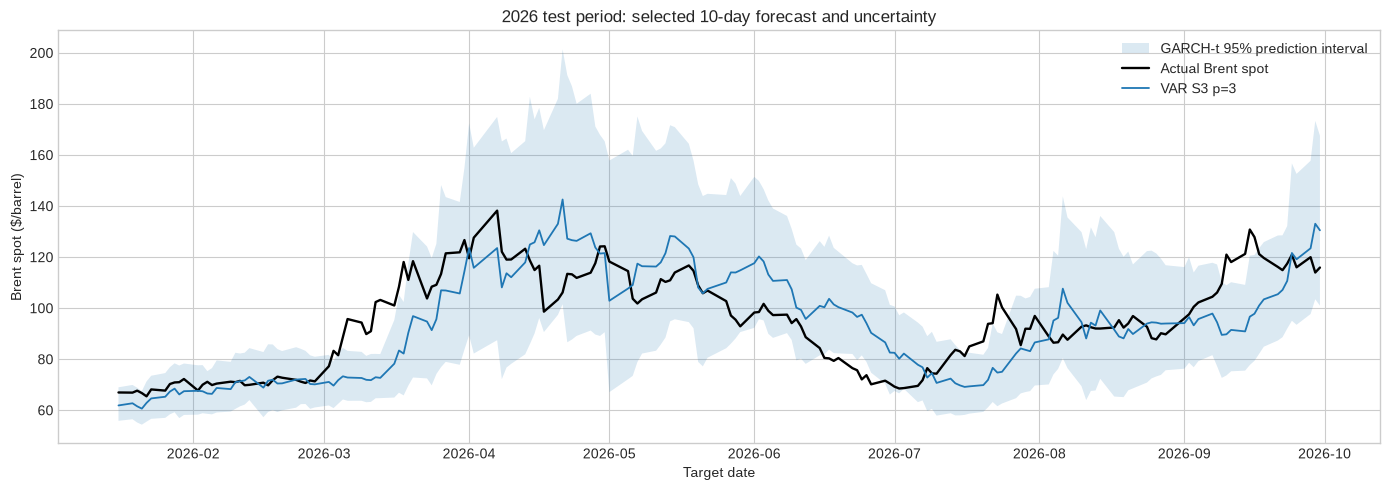

In [13]:
test_results = {}
for name in SHORTLIST:
    test_results[name] = run_target_window(
        MODELS[name], name, TEST_START, TEST_TARGET_END,
        origin_min=TEST_START, origin_max=TEST_END, fit_cutoff=TEST_FIT_CUTOFF)
N_TEST = assert_common(test_results)
assert WINNER == locked_winner
for res in test_results.values():
    assert (res.origin_date >= TEST_START).all() and (res.origin_date < TEST_END).all()
    assert (res.target_date <= TEST_TARGET_END).all()
    assert res.origin_date.min() == FIRST_TEST_ORIGIN
    assert res.target_date.min() == FIRST_TEST_TARGET

test_table = comparison_table(test_results)

test_paths = {name: daily_staggered_path(res) for name, res in test_results.items()}
economic_test = economic_display(test_table, SHORTLIST)
for p in [test_paths[WINNER]]:
    economic_periods.append({'stage': 'test', 'first_daily_return': p.index.min(),
                             'last_daily_return': p.index.max(), 'n_days': len(p)})
print('Test forecast pairs:', N_TEST, '; last target:', test_results[WINNER].target_date.max().date())
print('Validation-selected specification:', WINNER)
display(test_table[['MAE', 'RMSE', 'MAPE', 'MAPE_vs_RW_%', 'directional_accuracy',
                   'precision_up', 'recall_up', 'f1_up', 'precision_down', 'recall_down', 'f1_down',
                   'annualized_return', 'sharpe_ratio', 'max_drawdown', 'annual_turnover', 'n_days']].round(4))
display(economic_test.round(4))
display(test_results[WINNER].tail().round({'origin_price': 4, 'forecast': 4, 'actual': 4}))

# The family representatives and winner were locked before test evaluation.
# Holm corrections cover the entire prespecified shortlist per loss/benchmark table.
test_dm_tables = {}
for benchmark in ['Random Walk', 'Historical Mean']:
    for loss in ['ape', 'se']:
        key = f"{benchmark.lower().replace(' ', '_')}_{loss}_lag{H-1}"
        test_dm_tables[key] = dm_comparison(test_results, loss=loss, bandwidth=H-1, benchmark=benchmark)
        print(f'Test DM versus {benchmark}: {loss}, HAC lag {H-1}')
        display(test_dm_tables[key].round(5))

test_intervals = {method: add_intervals(test_results[WINNER], method, freeze=TEST_FIT_CUTOFF)
                  for method in ['GARCH', 'Constant vol']}
test_interval_table = pd.DataFrame({n: interval_metrics(r) for n, r in test_intervals.items()}).T
display(test_interval_table.round(4))
band = test_intervals['GARCH']
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(band.target_date, band.lower, band.upper, alpha=0.16, label='GARCH-t 95% prediction interval')
ax.plot(band.target_date, band.actual, color='black', lw=1.7, label='Actual Brent spot')
ax.plot(band.target_date, band.forecast, lw=1.3, label=WINNER)
ax.set(title='2026 test period: selected 10-day forecast and uncertainty', ylabel='Brent spot ($/barrel)', xlabel='Target date')
ax.legend(); plt.tight_layout(); plt.show()

## 11. Direct-Regression Coefficient Diagnostics

A prespecified direct regression is fitted through the last pre-validation observation. The dependent variable is the future 10-day log return. Predictors are the latest 1-day return and the preceding, non-overlapping 19-day return. Every training label is observed by the fitting date.

Newey–West/HAC standard errors with lag 10 address overlapping labels and heteroskedasticity. These coefficient statistics describe the regression; they do not establish causality or out-of-sample superiority. The selected model's final coefficients are reported in the conclusion.

In [14]:
def explanatory_ols(fit_idx):
    lp = np.log(df.brent_spot.to_numpy())
    start = fit_idx-LOOKBACK+1
    t = np.arange(start+20, fit_idx-H+1)
    X = pd.DataFrame({'latest_1d': lp[t]-lp[t-1], 'preceding_19d': lp[t-1]-lp[t-20]})
    y = lp[t+H]-lp[t]
    assert (t+H).max() <= fit_idx
    fit = sm.OLS(y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': H})
    ci = fit.conf_int()
    table = pd.DataFrame({'coefficient': fit.params, 'HAC_se': fit.bse, 't': fit.tvalues,
                          'p_value': fit.pvalues, 'CI_low': ci[0], 'CI_high': ci[1]})
    return fit, table

explain_idx = np.flatnonzero(df.index < VAL_START)[-1]
ols_fit, ols_table = explanatory_ols(explain_idx)
print('Training-only explanatory fit through', df.index[explain_idx].date(), '; observations:', int(ols_fit.nobs))
display(ols_table.round(5))

Training-only explanatory fit through 2023-12-29 ; observations: 2970


,coefficient,HAC_se,t,p_value,CI_low,CI_high
const,-0.00118,0.00421,-0.28004,0.77944,-0.00943,0.00708
latest_1d,-0.02637,0.22938,-0.11494,0.90849,-0.47593,0.42320
preceding_19d,0.09310,0.05357,1.73792,0.08223,-0.01189,0.19810


## 12. Final 10-Day Forecast

The validation-selected specification is refitted using information through **30 September 2026**. It predicts the price 10 observed Brent trading days later. This final-origin forecast is separate from the test, whose scored outcomes end on 30 September.

Prices are obtained as \(P_t\exp(\widehat y_{t,10})\), a plug-in central, median-style forecast rather than an unbiased conditional mean dollar price. Observed historical targets use the Brent calendar. Later actual prices are displayed for evaluation and excluded from the final-origin fit. Conditional prediction intervals omit some model and parameter uncertainty.

In [15]:
def final_forecast(origin_date, refit_latest=False):
    i = df.index.searchsorted(pd.Timestamp(origin_date), side='right')-1
    if i < LOOKBACK or df.index[i] != pd.Timestamp(origin_date):
        raise ValueError(f'Origin {origin_date} is not an available modelling observation; choose an observed date explicitly.')
    f = i if refit_latest else min(i, df.index.searchsorted(FIT_CUTOFF, side='right')-1)
    price = checked_model(MODELS[WINNER], WINNER)(df, i, H, f)
    lower, upper = interval_row(df, i, f, price, 'GARCH')
    if i+H < len(df):
        target, calendar_note = df.index[i+H], 'exact: 10 observed Brent days'
        actual = float(df.brent_spot.iloc[i+H])
    else:
        target = pd.bdate_range(df.index[i], periods=H+1)[-1]
        calendar_note, actual = 'approximate weekday date; actual Brent calendar not yet observed', np.nan
    row = {'model': WINNER, 'origin_date': df.index[i], 'fit_through': df.index[f],
           'target_date': target, 'calendar': calendar_note,
           'origin_price': float(df.brent_spot.iloc[i]), 'forecast': price,
           'forecast_log_return': float(np.log(price/df.brent_spot.iloc[i])),
           'lower_95': lower, 'upper_95': upper, 'actual_if_available': actual}
    return pd.DataFrame([row])

final = final_forecast(FINAL_ORIGIN)
display(final.T)
row = final.iloc[0]
print(f'Locked model: {WINNER}')
print(f'Origin {row.origin_date.date()}, Brent spot ${row.origin_price:.2f}/barrel')
print(f'10-day forecast for {row.target_date.date()}: ${row.forecast:.2f}/barrel')
print(f'Approximate GARCH-t 95% interval: ${row.lower_95:.2f}–${row.upper_95:.2f}/barrel')

,0
model,VAR S3 p=3
origin_date,2026-09-30 00:00:00
fit_through,2026-09-30 00:00:00
target_date,2026-10-14 00:00:00
calendar,exact: 10 observed Brent days
origin_price,115.91
forecast,118.098622
forecast_log_return,0.018706
lower_95,95.770963
upper_95,146.769365


Locked model: VAR S3 p=3
Origin 2026-09-30, Brent spot $115.91/barrel
10-day forecast for 2026-10-14: $118.10/barrel
Approximate GARCH-t 95% interval: $95.77–$146.77/barrel


### Updating the Forecast

The update procedure refits the same selected specification using the latest available observations. It is separate from the fixed historical evaluation and does not reselect the model using test performance. The forecast origin is the latest published observation date, which may lag the current date.

In [16]:
RUN_LATEST_UPDATE = False
latest = pd.DataFrame()
if RUN_LATEST_UPDATE:
    latest = final_forecast(df.index[-1], refit_latest=True)
    print('Daily update; this is separate from the fixed September assignment forecast.')
    display(latest.T)

## 13. Results Summary and Reproducibility

The analysis records the data hash, split boundaries, model specifications, forecast pairs, daily portfolio returns, evaluation tables, significance tests, intervals and final forecast. Staggered economic outputs are saved separately from the earlier non-overlapping-holdings analysis.

The imported economic functions are the shared repository implementations added at commit `b932ed9`. Daily paths are reconstructed for plotting and checked against their summary metrics. Conclusions and economic summaries are generated from the executed results.

In [17]:
val_table.to_csv(OUT/'validation_model_comparison.csv')
test_table.to_csv(OUT/'test_model_comparison.csv')
robustness.to_csv(OUT/'robustness.csv', index=False)
economic_validation.to_csv(OUT/'validation_daily_economic_summary.csv')
economic_test.to_csv(OUT/'test_daily_economic_summary.csv')
pd.DataFrame(economic_periods).to_csv(OUT/'daily_portfolio_windows.csv', index=False)
for stage, paths in [('validation', validation_paths), ('test', test_paths)]:
    pd.concat([path.reset_index().assign(model=name) for name, path in paths.items()],
              ignore_index=True).to_csv(OUT/f'{stage}_daily_portfolio_returns.csv', index=False)
interval_table.to_csv(OUT/'validation_interval_comparison.csv')
final.to_csv(OUT/'final_10day_forecast.csv', index=False)
if not latest.empty:
    latest.to_csv(OUT/'latest_10day_forecast.csv', index=False)
for key, table in dm_tables.items():
    table.to_csv(OUT/f'validation_dm_{key}.csv')
for key, table in test_dm_tables.items():
    table.to_csv(OUT/f'test_dm_{key}.csv')
test_interval_table.to_csv(OUT/'test_interval_comparison.csv')
for stage, results in [('validation', validation_results), ('test', test_results)]:
    pd.concat([r.assign(model=n) for n, r in results.items()], ignore_index=True).to_csv(
        OUT/f'{stage}_all_forecasts.csv', index=False)
for stage, results in [('validation', val_intervals), ('test', test_intervals)]:
    pd.concat([r.assign(interval_model=n) for n, r in results.items()], ignore_index=True).to_csv(
        OUT/f'{stage}_interval_forecasts.csv', index=False)
df.to_csv(OUT/'model_inputs.csv', index_label='date')
versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'statsmodels',
            'scikit-learn', 'xgboost', 'arch', 'matplotlib', 'yfinance', 'pandas-datareader']}
manifest = {'data_source': input_source, 'input_csv_sha256': DATA_HASH,
            'observation_start': str(raw.index[0].date()), 'observation_end': str(raw.index[-1].date()),
            'run_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'python': sys.version,
            'versions': versions, 'selection': selection_record,
            'economic_method': 'compare_models_staggered',
            'economic_source_commit': METRICS_SOURCE_COMMIT,
            'shared_source_sha256': {f: hashlib.sha256((ROOT/'src'/f).read_bytes()).hexdigest()
                                     for f in ['data.py', 'models.py', 'features.py', 'backtest.py', 'metrics.py']}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest, indent=2))

winner_gain = float(val_table.loc[WINNER, 'MAPE_vs_RW_%'])
significance = 'Random walk itself was selected; no superiority test applies.'
if WINNER != 'Random Walk':
    p = float(dm_tables[f'ape_lag{H-1}'].loc[WINNER, 'p_Holm'])
    significance = (f'Validation DM (APE, HAC lag {H-1}) Holm-adjusted p={p:.4f}. '
                    'This is a selection-period diagnostic, not independent confirmation.')
summary = f"""### Summary of Findings
- **Target:** Brent spot, {H} observed trading days ahead; daily rolling {LOOKBACK}-observation fits.
- **Model selection:** {WINNER}, chosen by validation MAPE through {SELECTION_END.date()}, before the first test origin.
- **Validation:** {N_VAL} forecasts; MAPE {val_table.loc[WINNER, 'MAPE']:.3f}%; relative improvement versus RW {winner_gain:+.2f}%.
- **Evidence:** {significance}
- **Holdout:** {N_TEST} target observations, {test_results[WINNER].target_date.min().date()}–{test_results[WINNER].target_date.max().date()}; MAPE {test_table.loc[WINNER, 'MAPE']:.3f}%. No reselection.
- **Final forecast:** ${row.forecast:.2f}/barrel for {row.target_date.date()}, from the {row.origin_date.date()} origin; GARCH-t interval ${row.lower_95:.2f}–${row.upper_95:.2f}.
- **Limitations:** overlapping forecast errors; daily-return dependence and staggered-portfolio assumptions; revised observation-dated data rather than historical release vintages; approximate interval/model uncertainty; spot trading proxy is not an investable futures backtest.
"""
display(Markdown(summary))
(OUT/'results_summary.md').write_text(summary)
print('Exported to:', OUT)
print('Evaluation tables and forecast CSVs saved.')

### Summary of Findings
- **Target:** Brent spot, 10 observed trading days ahead; daily rolling 3000-observation fits.
- **Model selection:** VAR S3 p=3, chosen by validation MAPE through 2025-12-31, before the first test origin.
- **Validation:** 497 forecasts; MAPE 4.045%; relative improvement versus RW +0.74%.
- **Evidence:** Validation DM (APE, HAC lag 9) Holm-adjusted p=1.0000. This is a selection-period diagnostic, not independent confirmation.
- **Holdout:** 179 target observations, 2026-01-16–2026-09-30; MAPE 11.532%. No reselection.
- **Final forecast:** $118.10/barrel for 2026-10-14, from the 2026-09-30 origin; GARCH-t interval $95.77–$146.77.
- **Limitations:** overlapping forecast errors; daily-return dependence and staggered-portfolio assumptions; revised observation-dated data rather than historical release vintages; approximate interval/model uncertainty; spot trading proxy is not an investable futures backtest.


Exported to: /workspace/Sample-Taxed/data/h10_outputs_staggered_val2024_2025_test2026
Evaluation tables and forecast CSVs saved.


## References

- FRED/EIA: [Europe Brent Spot Price FOB, DCOILBRENTEU](https://fred.stlouisfed.org/series/DCOILBRENTEU); WTI `DCOILWTICO`; broad USD index `DTWEXBGS`; VIX `VIXCLS`; OVX `OVXCLS`.
- Yahoo Finance: S&P 500 index, `^GSPC`.
- Diebold, F. X. and Mariano, R. S. (1995). Comparing Predictive Accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Harvey, D., Leybourne, S. and Newbold, P. (1997). Testing the Equality of Prediction Mean Squared Errors. *International Journal of Forecasting*, 13(2), 281–291.
- Newey, W. K. and West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, 55(3), 703–708.
- Bollerslev, T. (1986). Generalized Autoregressive Conditional Heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.

## 14. Model Selection and Conclusions

The final specification is selected using validation MAPE. Its test accuracy and significance relative to both benchmarks are evaluated separately from the daily trading strategy. Changing the economic evaluation method does not itself change point forecasts or the MAPE-based selection rule.

In [18]:
selected_family = SPECS[WINNER]['family']
family_explanation = {
    'Benchmark': 'The selected benchmark provides a deliberately simple forecast anchor.',
    'ARIMA': 'The model estimates daily-return dynamics and aggregates the iterated return forecasts over 10 days.',
    'Direct': 'The model directly regresses the next 10-day cumulative return on backward-looking return features.',
    'VAR': 'The joint system forecasts daily transformed variables; predicted Brent returns are aggregated over the horizon.',
    'Spread': 'The model links future cumulative Brent returns to the known relative Brent–WTI price spread.',
    'Ridge': 'Regularisation shrinks coefficients on standardised, backward-looking return and external features.',
    'XGBoost': 'A shallow boosted-tree model predicts the next 10-day cumulative return from origin-available features.',
    'GARCH': 'The point forecast compounds the estimated daily drift, while conditional volatility supplies uncertainty information.',
    'Combination': 'An equal-weight combination averages prespecified member forecasts in log-return space.',
}[selected_family]
benchmark_names = list(dict.fromkeys([WINNER, 'Random Walk', 'Historical Mean']))
benchmark_table = test_table.loc[benchmark_names, ['MAE', 'RMSE', 'MAPE', 'directional_accuracy']].copy()
benchmark_table['MAPE_vs_RW_%'] = 100*(1-benchmark_table.MAPE/test_table.loc['Random Walk', 'MAPE'])
benchmark_table['MAPE_vs_HM_%'] = 100*(1-benchmark_table.MAPE/test_table.loc['Historical Mean', 'MAPE'])
benchmark_table.to_csv(OUT/'selected_vs_benchmarks_test_metrics.csv')

inference_lines = []
for benchmark in ['Random Walk', 'Historical Mean']:
    if WINNER == benchmark:
        inference_lines.append(f'- **{benchmark}:** the selected model is this benchmark, so its forecasts coincide.')
        continue
    key = f"{benchmark.lower().replace(' ', '_')}_ape_lag{H-1}"
    evidence = test_dm_tables[key].loc[WINNER]
    gain = 100*(1-test_table.loc[WINNER, 'MAPE']/test_table.loc[benchmark, 'MAPE'])
    significant = np.isfinite(evidence.p_Holm) and evidence.p_Holm < 0.05
    if significant and evidence.mean_loss_gap < 0:
        verdict = 'Lower APE loss with a Holm-adjusted p-value below 0.05.'
    elif significant and evidence.mean_loss_gap > 0:
        verdict = 'Higher APE loss with a Holm-adjusted p-value below 0.05.'
    else:
        verdict = 'The test does not provide significant evidence of unequal APE loss at the 5% level.'
    inference_lines.append(f'- **Versus {benchmark}:** relative MAPE improvement {gain:+.3f}%; '
                           f'DM p={evidence.p_raw:.4f}, Holm p={evidence.p_Holm:.4f}. {verdict}')
result_text = f"""### Selected Specification: {WINNER}

{family_explanation}

- **Validation:** {N_VAL} forecasts with MAPE **{val_table.loc[WINNER, 'MAPE']:.4f}%**, versus random walk **{val_table.loc['Random Walk', 'MAPE']:.4f}%**. Selection outcomes end by **{VAL_TARGET_END.date()}**.
- **Test:** {N_TEST} common forecasts with target dates **{test_results[WINNER].target_date.min().date()}–{test_results[WINNER].target_date.max().date()}**. The selected model's MAPE is **{test_table.loc[WINNER, 'MAPE']:.4f}%**; RW is **{test_table.loc['Random Walk', 'MAPE']:.4f}%**, and historical mean **{test_table.loc['Historical Mean', 'MAPE']:.4f}%**.
- **Final forecast:** from the **{row.origin_date.date()}** origin, **${row.forecast:.2f}/barrel** for **{row.target_date.date()}**, with approximate GARCH-t 95% bounds **${row.lower_95:.2f}–${row.upper_95:.2f}**.

""" + '\n'.join(inference_lines) + """

The selected specification remains fixed regardless of the test ranking. Conclusions concern this retrospective sample: overlapping targets, source-data revisions, publication timing, model-selection uncertainty and dependence in daily portfolio returns constrain generalisation.
"""
display(Markdown(result_text))
display(benchmark_table.round(5))
(OUT/'conclusions.md').write_text(result_text)

trading_text = f"""### Daily Staggered Trading Results

The shared daily portfolio method opens one {H}-day signal per origin with 1/{H} of capital. Opposing positions are netted; trading costs are charged on changes in net exposure.

| Period | Daily observations | Annualised arithmetic return | Daily-return Sharpe | Max drawdown | Annual net turnover |
|---|---:|---:|---:|---:|---:|
| Validation | {int(val_table.loc[WINNER, 'n_days'])} | {100*val_table.loc[WINNER, 'annualized_return']:.2f}% | {val_table.loc[WINNER, 'sharpe_ratio']:.3f} | {100*val_table.loc[WINNER, 'max_drawdown']:.2f}% | {val_table.loc[WINNER, 'annual_turnover']:.2f} |
| Test | {int(test_table.loc[WINNER, 'n_days'])} | {100*test_table.loc[WINNER, 'annualized_return']:.2f}% | {test_table.loc[WINNER, 'sharpe_ratio']:.3f} | {100*test_table.loc[WINNER, 'max_drawdown']:.2f}% | {test_table.loc[WINNER, 'annual_turnover']:.2f} |

Annualised return is 252 times the average daily net return, **not** the realised cumulative gain or CAGR. These are stylised spot-return strategies; financing, futures rolls and slippage are omitted. Warm-up and terminal run-off days are excluded by the shared implementation. Conventional annualised Sharpe can still be affected by serial dependence in daily returns.

Trading profitability and point-forecast accuracy are different objectives. Economic results do not override the prespecified MAPE-based model selection or establish a statistically reliable trading edge.
"""
display(Markdown(trading_text))
(OUT/'conclusions.md').write_text(result_text+'\n\n'+trading_text)


### Selected Specification: VAR S3 p=3

The joint system forecasts daily transformed variables; predicted Brent returns are aggregated over the horizon.

- **Validation:** 497 forecasts with MAPE **4.0450%**, versus random walk **4.0754%**. Selection outcomes end by **2025-12-31**.
- **Test:** 179 common forecasts with target dates **2026-01-16–2026-09-30**. The selected model's MAPE is **11.5325%**; RW is **11.0218%**, and historical mean **11.0599%**.
- **Final forecast:** from the **2026-09-30** origin, **$118.10/barrel** for **2026-10-14**, with approximate GARCH-t 95% bounds **$95.77–$146.77**.

- **Versus Random Walk:** relative MAPE improvement -4.634%; DM p=0.2274, Holm p=1.0000. The test does not provide significant evidence of unequal APE loss at the 5% level.
- **Versus Historical Mean:** relative MAPE improvement -4.273%; DM p=0.2682, Holm p=1.0000. The test does not provide significant evidence of unequal APE loss at the 5% level.

The selected specification remains fixed regardless of the test ranking. Conclusions concern this retrospective sample: overlapping targets, source-data revisions, publication timing, model-selection uncertainty and dependence in daily portfolio returns constrain generalisation.


,MAE,RMSE,MAPE,directional_accuracy,MAPE_vs_RW_%,MAPE_vs_HM_%
model,,,,,,
VAR S3 p=3,11.11923,14.08061,11.53248,0.54190,-4.63378,-4.27261
Random Walk,10.70369,13.73357,11.02176,NaN,0.00000,0.34517
Historical Mean,10.73644,13.75726,11.05994,0.30168,-0.34637,0.00000


### Daily Staggered Trading Results

The shared daily portfolio method opens one 10-day signal per origin with 1/10 of capital. Opposing positions are netted; trading costs are charged on changes in net exposure.

| Period | Daily observations | Annualised arithmetic return | Daily-return Sharpe | Max drawdown | Annual net turnover |
|---|---:|---:|---:|---:|---:|
| Validation | 486 | 18.07% | 0.968 | -12.39% | 19.29 |
| Test | 168 | 109.64% | 1.577 | -50.42% | 3.30 |

Annualised return is 252 times the average daily net return, **not** the realised cumulative gain or CAGR. These are stylised spot-return strategies; financing, futures rolls and slippage are omitted. Warm-up and terminal run-off days are excluded by the shared implementation. Conventional annualised Sharpe can still be affected by serial dependence in daily returns.

Trading profitability and point-forecast accuracy are different objectives. Economic results do not override the prespecified MAPE-based model selection or establish a statistically reliable trading edge.


2291

## 15. Selected Model Against the Two Benchmarks

The following test-period comparison uses the same origin and target dates for the selected model, random walk and historical mean. Actual Brent prices are shown for reference. The lower panel reports trailing 20-forecast MAPE to reveal changes in relative accuracy over time; it is descriptive and does not alter model selection.

If a benchmark is itself selected, the corresponding forecasts coincide and are labelled accordingly rather than presented as distinct evidence.

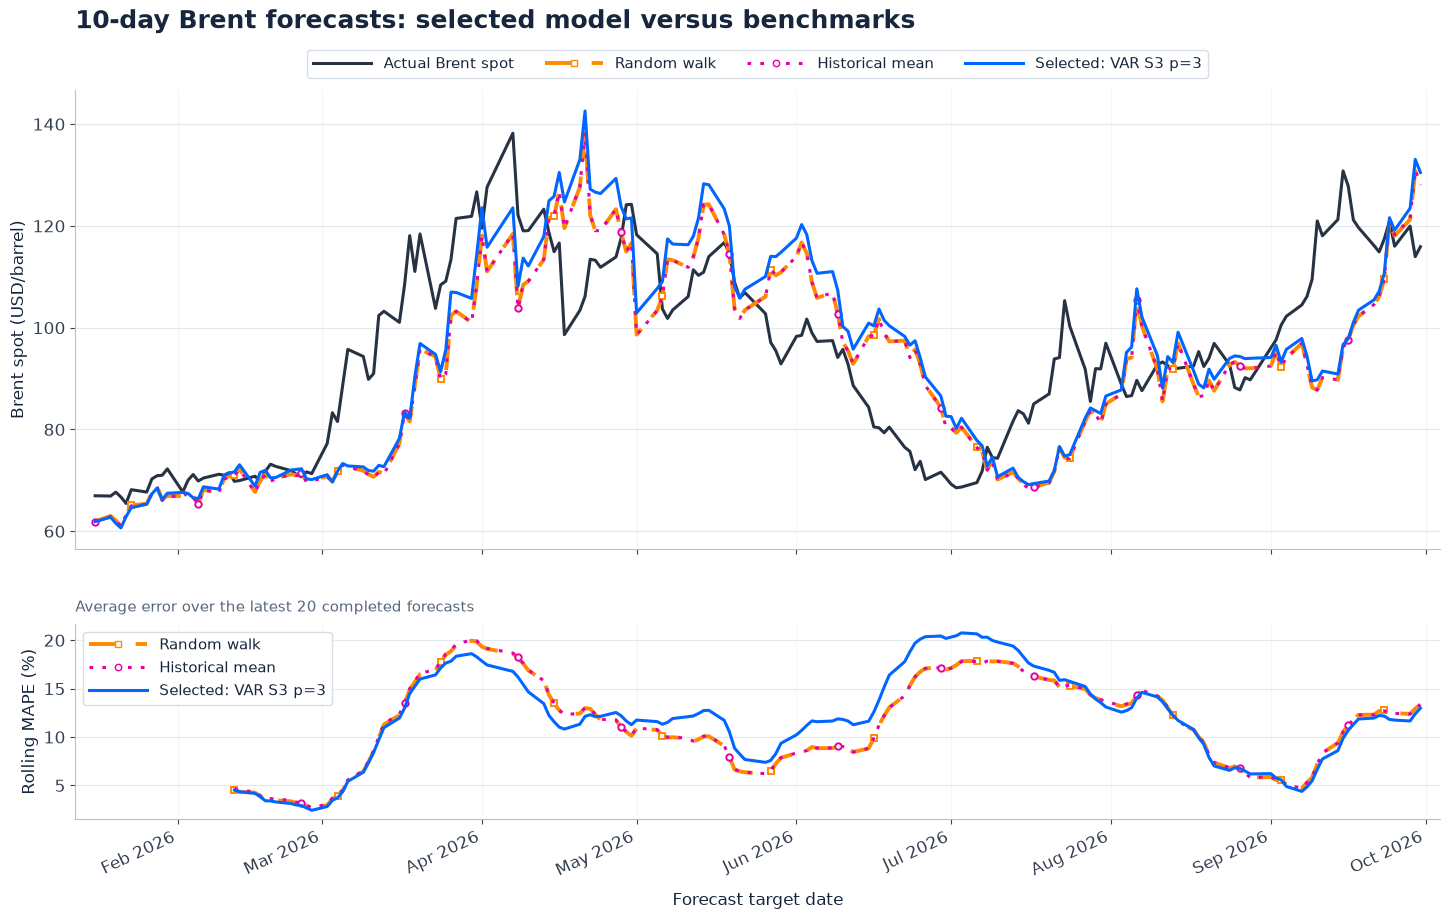

In [2]:
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
comparison = test_results[WINNER][['origin_date', 'target_date', 'origin_price', 'actual', 'forecast']].rename(columns={'forecast': 'selected_forecast'}).copy()
comparison['random_walk'] = test_results['Random Walk'].forecast.to_numpy()
comparison['historical_mean'] = test_results['Historical Mean'].forecast.to_numpy()
comparison['selected_model'] = WINNER
comparison.to_csv(OUT/'selected_vs_benchmarks_test_forecasts.csv', index=False)

model = WINNER
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.titlesize':17,
                     'axes.labelsize':12,'legend.fontsize':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.edgecolor':'#B8C2CF',
                     'xtick.color':'#364152','ytick.color':'#364152',
                     'text.color':'#17263D','axes.labelcolor':'#17263D'})
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,gridspec_kw={'height_ratios':[2.35,1]},facecolor='white')
colors={'actual':'#273343','selected':'#0066FF','rw':'#FF8A00','hm':'#E600A5'}
axes[0].plot(comparison.target_date,comparison.actual,color=colors['actual'],lw=2.2,label='Actual Brent spot',zorder=2)
# Alternating dash patterns and sparse offset markers distinguish near-coincident benchmarks.
styles=[('Random walk','random_walk',colors['rw'],(0,(8,4)),2.8,'s',(5,14)),
        ('Historical mean','historical_mean',colors['hm'],(0,(1.2,3.0)),2.2,'o',(0,14)),
        (f'Selected: {model}','selected_forecast',colors['selected'],'-',2.2,None,None)]
for name,column,color,style,lw,marker,markevery in styles:
    kwargs=dict(color=color,ls=style,lw=lw,label=name,zorder=4 if column=='selected_forecast' else 3)
    if marker:
        kwargs.update(marker=marker,markevery=markevery,markersize=4.6,
                      markerfacecolor='white',markeredgecolor=color,markeredgewidth=1.4)
    axes[0].plot(comparison.target_date,comparison[column],**kwargs)
    ape=(comparison.actual-comparison[column]).abs()/comparison.actual*100
    axes[1].plot(comparison.target_date,ape.rolling(20).mean(),**kwargs)
fig.suptitle('10-day Brent forecasts: selected model versus benchmarks',x=.075,y=.99,ha='left',fontsize=18,fontweight='bold')
axes[0].set_ylabel('Brent spot (USD/barrel)')
axes[1].set_ylabel('Rolling MAPE (%)')
axes[1].set_title('Average error over the latest 20 completed forecasts',loc='left',fontsize=11,color='#58677C',pad=9)
axes[1].set_xlabel('Forecast target date',labelpad=9)
handles=[Line2D([0],[0],color=colors['actual'],lw=2.2,label='Actual Brent spot')]
for name,column,color,style,lw,marker,markevery in styles:
    handles.append(Line2D([0],[0],color=color,ls=style,lw=lw,marker=marker,
                          markerfacecolor='white',markeredgecolor=color,markersize=4.6,label=name))
axes[0].legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,1.01),ncol=4,
               frameon=True,facecolor='white',edgecolor='#D6DDE6',framealpha=.97,
               handlelength=3.8,columnspacing=2.0)
axes[1].legend(handles=handles[1:],loc='upper left',frameon=True,edgecolor='#D6DDE6',
               facecolor='white',framealpha=.97,handlelength=3.8)
for ax in axes:
    ax.set_facecolor('white')
    ax.grid(axis='y',color='#E2E8F0',lw=.8)
    ax.grid(axis='x',color='#F1F4F8',lw=.6)
    ax.margins(x=.015)
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.subplots_adjust(left=.075,right=.985,top=.90,bottom=.09,hspace=.23)
for label in axes[1].get_xticklabels():label.set_rotation(25);label.set_ha('right')

fig.savefig(OUT/'selected_model_vs_benchmarks_test.png', dpi=220, bbox_inches='tight', facecolor='white')
fig.savefig(OUT/'selected_model_vs_benchmarks_test.pdf', bbox_inches='tight', facecolor='white')
plt.show()


## 16. Daily Staggered Portfolio Comparison

The selected model and benchmarks are compared using the same one-day return dates and net-exposure cost convention. The equity curves compound measured daily net returns; the lower panel shows the net positions producing them. Random walk makes no directional bet and therefore remains in cash.

Only the shared method's full-history measurement window is shown. Its boundary treatment excludes start-up and terminal run-off returns. These portfolio curves answer a different question from the preceding price-forecast plot.

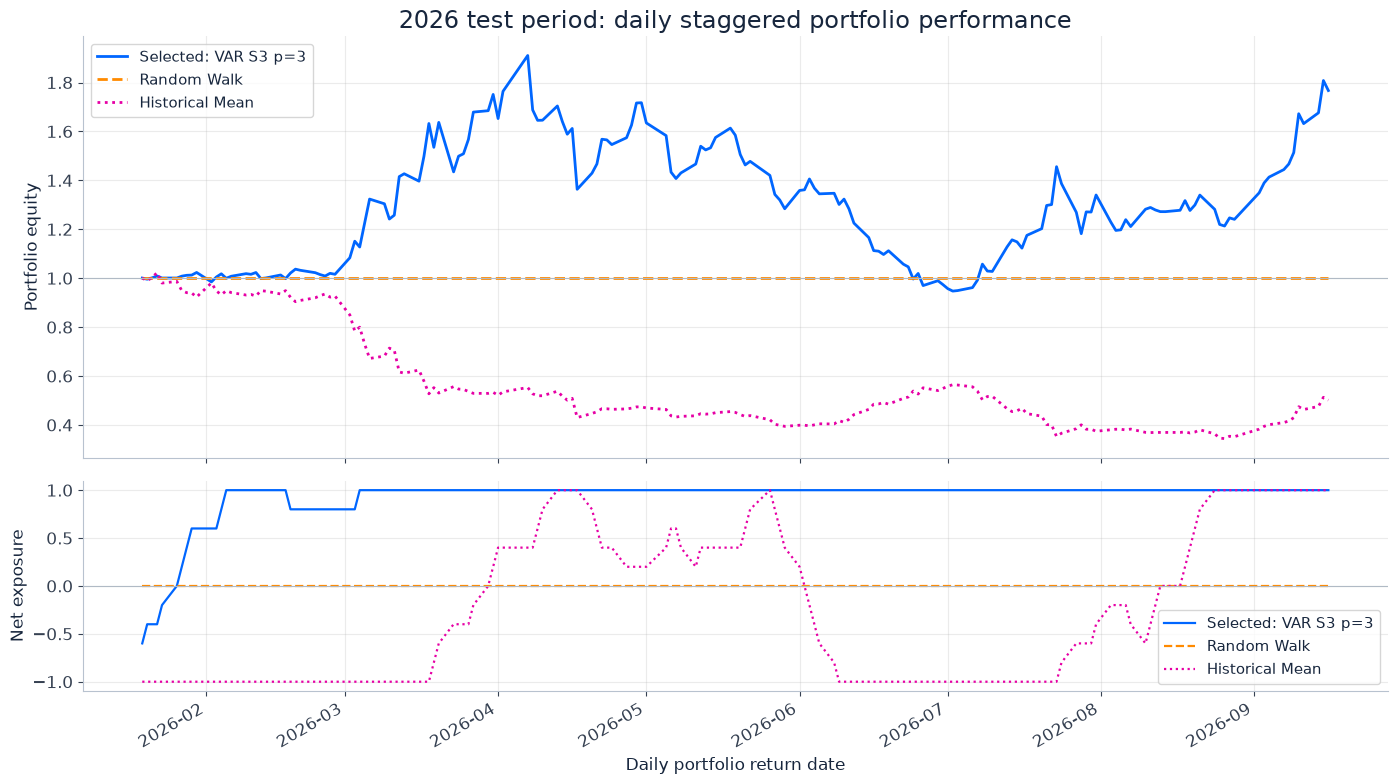

In [3]:
portfolio_names = list(dict.fromkeys([WINNER, 'Random Walk', 'Historical Mean']))
portfolio_colors = {WINNER: '#0066FF', 'Random Walk': '#FF8A00', 'Historical Mean': '#E600A5'}
portfolio_styles = {WINNER: '-', 'Random Walk': '--', 'Historical Mean': ':'}
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for name in portfolio_names:
    p = test_paths[name]
    label = f'Selected: {name}' if name == WINNER else name
    axes[0].plot(p.index, p.equity, label=label, color=portfolio_colors[name], ls=portfolio_styles[name], lw=2)
    axes[1].plot(p.index, p.net_exposure, label=label, color=portfolio_colors[name], ls=portfolio_styles[name], lw=1.6)
axes[0].axhline(1, color='#B0BAC5', lw=.8)
axes[0].set(title='2026 test period: daily staggered portfolio performance', ylabel='Portfolio equity')
axes[1].axhline(0, color='#B0BAC5', lw=.8)
axes[1].set(ylabel='Net exposure', xlabel='Daily portfolio return date', ylim=(-1.1, 1.1))
for ax in axes:
    ax.grid(alpha=.25); ax.legend(loc='best')
fig.autofmt_xdate(); plt.tight_layout()
fig.savefig(OUT/'selected_model_daily_staggered_portfolio.png', dpi=200, bbox_inches='tight')
fig.savefig(OUT/'selected_model_daily_staggered_portfolio.pdf', bbox_inches='tight')
plt.show()